# OmniDoc-Mamba v3: Patched End-to-End Notebook
## Visually-Rich Document Understanding with State-Space Models

**Author**: Arjun (IIT Jodhpur, M.Tech DCS) | **Thesis**: Visually-Rich Document Understanding (VRDU)

### What changed from v2 (and why)

| # | Fix | v2 problem |
|---|-----|-----------|
| 1 | **Real masked patch modeling**: masked patches are replaced by a learned `[MASK]` token *before* the encoder; MAE-style per-patch target normalisation; loss only on masked *ink* patches | v2 masked only the loss, so the model copied its input (loss 0.02 on mostly-white pages) |
| 2 | **Visual tokens really reach the decoder**: pooled visual tokens are prepended as `inputs_embeds` (same path for training and generation); **real LoRA via `peft`** | v2 mean-pooled 980 tokens into one vector added to the final hidden state; "LoRA" was a logit bias; train/generate paths differed (hence empty output) |
| 3 | **Honest evaluation**: free-running `generate()`, CER / WER on the reading task, dev split for model selection, blank/shuffled-image controls | v2 scored teacher-forced argmax and set-F1, then tabulated it against published entity-level F1 |
| 4 | **Efficiency benchmark** (Transformer vs SSM, memory + time vs sequence length) | The 88 % memory / 2x throughput claims had no measurement behind them |
| + | Real `mamba_ssm` blocks when available (else a clearly-labelled **non-Mamba** fallback); no 16-token chunk resets (true SFBS is an opt-in two-level scan) | v2 "Mamba" was a fixed-decay EMA and state reset every 16 tokens |
| + | **Prompt-gate label leak removed**: the gate is computed from the prompt tokens only | v2 averaged the embeddings of prompt **and answer** tokens into the visual gate during training |
| + | EOS token learned; best-on-dev checkpoint; separate optimiser per stage; stage-A uses the same gate as stage-B | |

See the last cell for what is **still not fixed**. Outputs from v2 were cleared because they came from the old code.

### v3.1 (fix for the "Date: Date: Date: ..." collapse)
The collapsed output means the model fell back to its language-model prior and **never learned to read the page**: a from-scratch visual encoder cannot learn OCR from ~134 forms. v3.1 changes:

| Fix | Why |
|---|---|
| **Stage A2: synthetic reading pretraining** - thousands of rendered pages with *known* text, same prompt / pipeline / loss as FUNSD fine-tuning, with a **synthetic CER readout every epoch** | Gives the encoder enough labelled data to learn to read. If synthetic CER does not fall, the architecture or pipeline is broken, independent of FUNSD |
| **Higher resolution**: crop 336 px (canvas 672 px, was 448 px) via `OMNIDOC_CROP`; visual-token pooling now adapts so the decoder prefix stays under the decoder's context | FUNSD text was about 4 px tall after letterboxing |
| **Decoding guard**: `no_repeat_ngram_size=3`, `repetition_penalty=1.2` | Stops degenerate loops. **Cosmetic only**: it hides the symptom, not the cause, so report CER, not pretty text |


## Step 1: Connect VS Code to the college A30 GPU

Open this notebook from the remote Linux server in VS Code (Remote - SSH), then select `Python (omnidoc)`. Run cells from top to bottom. In the VS Code remote terminal, the environment should report Python 3.10.12, PyTorch 2.1.2+cu118, CUDA available, and NVIDIA A30.

Before running the notebook, the project setup cell stores datasets, Hugging Face cache, checkpoints, and results under `/scratch/m25mac003/omnidoc_outputs`.

Dependencies must already be installed in the cluster `omnidoc` environment; this notebook does not install packages. Keep `OMNIDOC_4BIT=0` for the default `distilgpt2` model.


In [2]:
# Verify this notebook is running in the cluster's omnidoc GPU environment.
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not visible")


Python: /csehome/m25mac003/venvs/omnidoc/bin/python
PyTorch: 2.1.2+cu118
CUDA available: True
GPU: NVIDIA A30


In [3]:
# Dependencies should already be installed in the cluster's Python (omnidoc) environment.
# Do not run pip install here; it could change the cluster-provided PyTorch/CUDA setup.
print("Using the selected cluster environment; no packages installed by this notebook.")


Using the selected cluster environment; no packages installed by this notebook.


In [4]:
# Optional preflight for real Mamba. This cell never installs packages.
USE_REAL_MAMBA = False
_MambaBlock = None
_probe = None

if not torch.cuda.is_available():
    print("CUDA is not available; Mamba check skipped.")
else:
    try:
        from mamba_ssm import Mamba as _MambaBlock

        _probe = _MambaBlock(
            d_model=32, d_state=16, d_conv=4, expand=2
        ).to(device="cuda", dtype=torch.float16)

        _x = torch.randn(1, 16, 32, device="cuda", dtype=torch.float16)
        with torch.inference_mode():
            _y = _probe(_x)

        if _y.shape != _x.shape:
            raise RuntimeError(f"Unexpected Mamba output shape: {_tuple(_y.shape)}")

        USE_REAL_MAMBA = True
        print("Mamba import and GPU forward pass succeeded.")

    except Exception as exc:
        _MambaBlock = None
        USE_REAL_MAMBA = False
        print(
            f"Real Mamba unavailable ({type(exc).__name__}: {exc}). "
            "The notebook will use its labeled EMA fallback."
        )

    finally:
        if _probe is not None:
            del _probe
        if "_x" in globals():
            del _x
        if "_y" in globals():
            del _y
        torch.cuda.empty_cache()

Real Mamba unavailable (ModuleNotFoundError: No module named 'mamba_ssm'). The notebook will use its labeled EMA fallback.


In [5]:
# %pip install -q "numpy<2" "transformers==4.44.2" "datasets==2.21.0" scikit-learn "gradio==4.44.1" "accelerate==0.34.2" "peft==0.13.2" pymupdf jiwer ipywidgets
# print("Notebook dependencies installed; PyTorch was left unchanged.")

In [6]:
# %pip install seaborn

In [7]:
# Core imports and reproducibility setup
import os
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import sys
import json
import random
import warnings
import io
from pathlib import Path
from typing import Dict, List, Tuple, Optional
from collections import defaultdict

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Core imports successful")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Core imports successful
PyTorch: 2.1.2+cu118
CUDA available: True


In [8]:
import os
from pathlib import Path

BASE_DIR = Path("/scratch/m25mac003/omnidoc_outputs")
DATA_DIR = BASE_DIR / "data"
MODELS_DIR = BASE_DIR / "models"
RESULTS_DIR = BASE_DIR / "results"
NOTEBOOKS_DIR = BASE_DIR / "notebooks"

for directory in (DATA_DIR, MODELS_DIR, RESULTS_DIR, NOTEBOOKS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(DATA_DIR / "hf_cache")
os.environ["HF_HUB_CACHE"] = str(DATA_DIR / "hf_cache" / "hub")

print(f"Project storage root: {BASE_DIR}")
print(f"Data: {DATA_DIR} | Models: {MODELS_DIR} | Results: {RESULTS_DIR}")

Project storage root: /scratch/m25mac003/omnidoc_outputs
Data: /scratch/m25mac003/omnidoc_outputs/data | Models: /scratch/m25mac003/omnidoc_outputs/models | Results: /scratch/m25mac003/omnidoc_outputs/results


## Step 2: Dataset Ingestion & Preprocessing

## Dataset and cluster notes

The notebook downloads FUNSD and the `distilgpt2` model from Hugging Face, so the compute node needs internet access or those files must already be cached. If downloads are blocked, ask the department for its approved cache or transfer method. The synthetic fallback is only a smoke-test dataset and must not be used for research results.

Data and checkpoints are stored under `/scratch/m25mac003/omnidoc_outputs`. The cluster's A30 has about 24 GiB GPU memory; the notebook defaults to a conservative batch size and mixed precision. Training can take a long time, especially when the optional Mamba kernels are unavailable.


In [9]:
# Download FUNSD and normalize its records.
from datasets import load_dataset

USE_ONLINE_DATA = True
USE_SYNTHETIC_FALLBACK = False  # Set True only for a smoke test
DATASET_NAME = "nielsr/funsd"


class SyntheticDocumentDataset:
    """Small synthetic dataset for checking the pipeline only."""

    def __init__(self, num_samples=8, image_size=(256, 256)):
        self.data = []

        for sample_index in range(num_samples):
            image_array = np.random.randint(
                200, 256, image_size, dtype=np.uint8
            )
            image_array[::32, :] = np.random.randint(
                50, 150, (len(image_array[::32]), image_size[1])
            )

            boxes, values = [], []
            for field_index in range(5):
                x1 = 10 + field_index * 35
                y1 = 20 + field_index * 25
                x2 = min(x1 + 28, image_size[1] - 1)
                y2 = min(y1 + 14, image_size[0] - 1)

                boxes.append({
                    "x": [x1, x1, x2, x2],
                    "y": [y1, y2, y2, y1],
                    "text": f"field_{field_index}",
                })
                values.append(f"value_{field_index}_{sample_index}")

            self.data.append({
                "image": Image.fromarray(image_array).convert("RGB"),
                "boxes": boxes,
                "values": values,
                "task_type": "kie",
            })

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        return self.data[index]


def _as_words(value):
    """Normalize token fields represented as strings, lists, or dictionaries."""
    if value is None:
        return []

    if isinstance(value, str):
        return [value]

    if isinstance(value, dict):
        value = value.get("text", value.get("word", ""))
        if isinstance(value, (list, tuple)):
            return [str(item) for item in value]
        return [str(value)]

    words = []
    for item in value:
        if isinstance(item, dict):
            words.append(str(item.get("text", item.get("word", ""))))
        else:
            words.append(str(item))

    return words


def normalize_funsd_split(split):
    """Convert FUNSD records to the local schema.

    The nielsr/funsd dataset stores bounding boxes in image-pixel coordinates.
    """
    documents = []

    for record in split:
        image = record.get("image")
        if image is None:
            continue

        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.asarray(image))

        image = image.convert("RGB")
        width, height = image.size

        words = _as_words(record.get("words"))
        raw_boxes = record.get("bboxes", record.get("boxes", [])) or []

        boxes, values = [], []

        for word, raw_box in zip(words, raw_boxes):
            if isinstance(raw_box, dict):
                raw_box = raw_box.get("box", raw_box.get("bbox", []))

            coords = np.asarray(raw_box, dtype=np.float64)
            if coords.shape != (4,) or not np.isfinite(coords).all():
                continue

            x1, y1, x2, y2 = coords

            # FUNSD boxes are already in pixels; clip to the page bounds.
            x1, x2 = np.clip([x1, x2], 0, width)
            y1, y2 = np.clip([y1, y2], 0, height)

            if x2 <= x1 or y2 <= y1:
                continue

            boxes.append({
                "x": [x1, x1, x2, x2],
                "y": [y1, y2, y2, y1],
                "text": word,
            })
            values.append(word)

        if boxes:
            documents.append({
                "image": image,
                "boxes": boxes,
                "values": values,
                "task_type": "kie",
            })

    return documents


funsd_path = DATA_DIR / "funsd"
funsd_path.mkdir(parents=True, exist_ok=True)

train_documents = []
validation_documents = []

if USE_ONLINE_DATA:
    try:
        funsd_dataset = load_dataset(
            DATASET_NAME,
            cache_dir=str(DATA_DIR / "hf_cache"),
        )

        train_documents = normalize_funsd_split(funsd_dataset["train"])
        validation_documents = normalize_funsd_split(funsd_dataset["test"])

        if not train_documents or not validation_documents:
            raise RuntimeError(
                "FUNSD loaded, but one or both splits normalized to zero documents."
            )

        print(
            f"Loaded {DATASET_NAME}: "
            f"{len(train_documents)} train / "
            f"{len(validation_documents)} test documents"
        )

    except Exception as error:
        if not USE_SYNTHETIC_FALLBACK:
            raise RuntimeError(
                "FUNSD could not be loaded. Check cluster internet access, "
                "the Hugging Face cache, and the dataset format. Synthetic "
                "fallback is only for smoke tests."
            ) from error

        print(f"FUNSD unavailable; using synthetic smoke-test data. Reason: {error}")
        train_documents = []
        validation_documents = []

if not train_documents or not validation_documents:
    if not USE_SYNTHETIC_FALLBACK:
        raise RuntimeError(
            "No real FUNSD documents are available. Set "
            "USE_SYNTHETIC_FALLBACK=True only to smoke-test the pipeline."
        )

    fallback = SyntheticDocumentDataset(
        num_samples=16,
        image_size=(256, 256),
    ).data

    train_documents = fallback[:12]
    validation_documents = fallback[12:]

    print(
        f"Using synthetic smoke-test data: "
        f"{len(train_documents)} train / "
        f"{len(validation_documents)} validation documents"
    )

Loaded nielsr/funsd: 149 train / 50 test documents


In [10]:
# Optional CORD download for a separate receipt-parsing experiment.
USE_CORD_DATA = False
CORD_DATASET_NAME = "naver-clova-ix/cord-v2"
cord_dataset = None

if USE_CORD_DATA:
    cord_cache = DATA_DIR / "cord" / "hf_cache"
    cord_cache.mkdir(parents=True, exist_ok=True)

    try:
        cord_dataset = load_dataset(
            CORD_DATASET_NAME,
            cache_dir=str(cord_cache),
        )

        split_sizes = {
            split_name: len(split_data)
            for split_name, split_data in cord_dataset.items()
        }
        print(f"Loaded {CORD_DATASET_NAME}: {split_sizes}")
        print(
            "CORD is loaded in its raw schema; it must be normalized "
            "before use with the FUNSD pipeline."
        )

    except Exception as error:
        raise RuntimeError(
            f"CORD download failed: {type(error).__name__}: {error}"
        ) from error
else:
    print("CORD download disabled; continuing with FUNSD.")

CORD download disabled; continuing with FUNSD.


In [11]:
funsd_train_documents = list(train_documents)
funsd_test_documents = list(validation_documents)

In [12]:
# Make a deterministic dev split from the original FUNSD training set.
# The official test split is reserved for final reporting.
if len(funsd_train_documents) < 2:
    raise ValueError("FUNSD needs at least two training documents to create a dev split.")

if not funsd_test_documents:
    raise ValueError("The official FUNSD test split is empty.")

_rng = random.Random(42)
_order = list(range(len(funsd_train_documents)))
_rng.shuffle(_order)

_n_dev = min(
    max(1, round(0.1 * len(funsd_train_documents))),
    len(funsd_train_documents) - 1,
)

dev_indices = _order[:_n_dev]
train_indices = _order[_n_dev:]

train_documents = [funsd_train_documents[i] for i in train_indices]
dev_documents = [funsd_train_documents[i] for i in dev_indices]
validation_documents = list(funsd_test_documents)

print(
    f"Train: {len(train_documents)} | "
    f"Dev (model selection): {len(dev_documents)} | "
    f"Test (final only): {len(validation_documents)}"
)

Train: 134 | Dev (model selection): 15 | Test (final only): 50


In [13]:
# Dynamic multi-view cropping and image/PDF handling.
import io

CROP_SIZE = int(os.environ.get("OMNIDOC_CROP", 336))
GRID_SIZE = 2

if CROP_SIZE <= 0:
    raise ValueError(f"OMNIDOC_CROP must be positive; got {CROP_SIZE}.")
if GRID_SIZE <= 0:
    raise ValueError(f"GRID_SIZE must be positive; got {GRID_SIZE}.")


def _to_rgb_image(image):
    """Convert paths, arrays, tensors, and PIL images to RGB PIL images."""
    if isinstance(image, (str, Path)):
        with Image.open(image) as opened:
            return opened.convert("RGB")

    if torch.is_tensor(image):
        image = image.detach().cpu()

        if image.ndim == 4:
            if image.shape[0] != 1:
                raise ValueError(
                    f"Expected one image, got tensor batch shape {tuple(image.shape)}."
                )
            image = image[0]

        if image.ndim == 3 and image.shape[0] in (1, 3, 4) and image.shape[-1] not in (1, 3, 4):
            image = image.permute(1, 2, 0)

        if image.dtype != torch.uint8:
            image = image.float()

        image = image.numpy()

    if isinstance(image, Image.Image):
        return image.convert("RGB")

    image_array = np.asarray(image)
    if image_array.size == 0:
        raise ValueError("Cannot convert an empty image.")

    if np.issubdtype(image_array.dtype, np.floating):
        image_array = np.nan_to_num(
            image_array, nan=255.0, posinf=255.0, neginf=0.0
        )
        min_value = float(image_array.min())
        max_value = float(image_array.max())

        if min_value >= 0.0 and max_value <= 1.0:
            image_array = image_array * 255.0
        elif min_value >= -1.0 and max_value <= 1.0:
            image_array = (image_array + 1.0) * 127.5

    image_array = np.clip(image_array, 0, 255).astype(np.uint8)

    if image_array.ndim == 2:
        image_array = np.repeat(image_array[..., None], 3, axis=-1)
    elif image_array.ndim == 3 and image_array.shape[-1] == 1:
        image_array = np.repeat(image_array, 3, axis=-1)
    elif image_array.ndim == 3 and image_array.shape[-1] == 4:
        rgba = Image.fromarray(image_array)
        rgb = Image.new("RGB", rgba.size, (255, 255, 255))
        rgb.paste(rgba, mask=rgba.getchannel("A"))
        return rgb
    elif image_array.ndim != 3 or image_array.shape[-1] != 3:
        raise ValueError(
            f"Expected grayscale, RGB, or RGBA image; got shape {image_array.shape}."
        )

    return Image.fromarray(image_array).convert("RGB")


def _document_path(document):
    """Get a local path from common path and uploaded-file representations."""
    if isinstance(document, (str, Path)):
        return Path(document)

    if isinstance(document, dict):
        candidate = document.get("path") or document.get("name")
        if candidate:
            return Path(candidate)

    candidate = getattr(document, "name", None) or getattr(document, "path", None)
    if candidate:
        return Path(candidate)

    return None


def load_document_pages(document, max_pages=12, pdf_dpi=150):
    """Load an image or PDF as RGB pages."""
    if document is None:
        return []

    max_pages = int(max_pages)
    pdf_dpi = int(pdf_dpi)

    if max_pages <= 0:
        raise ValueError("max_pages must be positive.")
    if pdf_dpi <= 0:
        raise ValueError("pdf_dpi must be positive.")

    source_path = _document_path(document)

    if source_path is not None and source_path.suffix.lower() == ".pdf":
        try:
            import fitz
        except ImportError as error:
            raise RuntimeError(
                "PDF support requires PyMuPDF (`pymupdf`) in the active kernel."
            ) from error

        pages = []
        scale = pdf_dpi / 72.0
        matrix = fitz.Matrix(scale, scale)

        with fitz.open(str(source_path)) as pdf:
            for page_index in range(min(len(pdf), max_pages)):
                pixmap = pdf[page_index].get_pixmap(
                    matrix=matrix,
                    colorspace=fitz.csRGB,
                    alpha=False,
                )
                pages.append(
                    Image.frombytes(
                        "RGB",
                        (pixmap.width, pixmap.height),
                        pixmap.samples,
                    )
                )

        return pages

    if source_path is not None and source_path.exists():
        return [_to_rgb_image(source_path)]

    if hasattr(document, "read"):
        document.seek(0)
        with Image.open(document) as opened:
            return [opened.convert("RGB")]

    return [_to_rgb_image(document)]


def _letterbox_image(image, size):
    """Resize without distortion and center-pad to a square white canvas."""
    size = int(size)
    if size <= 0:
        raise ValueError("Letterbox size must be positive.")

    image = _to_rgb_image(image)
    scale = min(size / image.width, size / image.height)

    resized_width = max(1, round(image.width * scale))
    resized_height = max(1, round(image.height * scale))
    resized = image.resize(
        (resized_width, resized_height),
        Image.Resampling.LANCZOS,
    )

    canvas = Image.new("RGB", (size, size), (255, 255, 255))
    offset = ((size - resized.width) // 2, (size - resized.height) // 2)
    canvas.paste(resized, offset)
    return canvas


def dynamic_crop_images(image, crop_size=CROP_SIZE, grid_size=GRID_SIZE):
    """Return grid-local crops followed by one global-context view."""
    crop_size = int(crop_size)
    grid_size = int(grid_size)

    if crop_size <= 0 or grid_size <= 0:
        raise ValueError("crop_size and grid_size must both be positive.")

    canvas = _letterbox_image(image, crop_size * grid_size)
    image_array = np.asarray(canvas)

    crops = []
    for row in range(grid_size):
        for col in range(grid_size):
            y_start = row * crop_size
            x_start = col * crop_size
            crops.append(
                image_array[
                    y_start:y_start + crop_size,
                    x_start:x_start + crop_size,
                ].copy()
            )

    global_view = _letterbox_image(canvas, crop_size)
    crops.append(np.asarray(global_view).copy())
    return crops


# Small preprocessing check
test_img = Image.fromarray(
    np.random.randint(0, 256, (512, 768, 3), dtype=np.uint8)
)
crops = dynamic_crop_images(test_img)

print(
    f"Pixel views: {len(crops)} | "
    f"each shape: {crops[0].shape} | "
    f"RGB: {crops[0].shape[-1] == 3}"
)

Pixel views: 5 | each shape: (336, 336, 3) | RGB: True


In [14]:
# Scale-invariant topological mesh.
# FUNSD boxes are in pixel coordinates; map their centers into a fixed grid.

def create_topological_mesh(boxes: List[Dict], image_size, grid_resolution=100):
    """Map each bounding box center to row/column indices in a fixed grid."""
    grid_resolution = int(grid_resolution)
    if grid_resolution <= 0:
        raise ValueError("grid_resolution must be positive.")

    if isinstance(image_size, int):
        width = height = image_size
    else:
        if len(image_size) != 2:
            raise ValueError("image_size must be an integer or (width, height).")
        width, height = image_size

    width, height = float(width), float(height)
    if width <= 0 or height <= 0:
        raise ValueError(f"Image dimensions must be positive; got {(width, height)}.")

    topological_boxes = []

    for index, box in enumerate(boxes):
        try:
            x = np.asarray(box["x"], dtype=np.float64)
            y = np.asarray(box["y"], dtype=np.float64)
        except (KeyError, TypeError, ValueError) as error:
            raise ValueError(f"Box {index} must contain numeric 'x' and 'y' coordinates.") from error

        if x.size == 0 or y.size == 0 or not np.isfinite(x).all() or not np.isfinite(y).all():
            raise ValueError(f"Box {index} has empty or non-finite coordinates.")

        # Center of the box's enclosing rectangle.
        center_x = (float(x.min()) + float(x.max())) / 2
        center_y = (float(y.min()) + float(y.max())) / 2

        col_idx = int(np.clip(center_x / width * grid_resolution, 0, grid_resolution - 1))
        row_idx = int(np.clip(center_y / height * grid_resolution, 0, grid_resolution - 1))

        topological_boxes.append({
            "row_idx": row_idx,
            "col_idx": col_idx,
            "text": box.get("text", ""),
            "original_box": box,
        })

    return topological_boxes


test_boxes = [
    {"x": [10, 10, 40, 40], "y": [10, 30, 30, 10], "text": "field_1"},
    {"x": [100, 100, 150, 150], "y": [100, 140, 140, 100], "text": "field_2"},
]
topo_boxes = create_topological_mesh(test_boxes, image_size=(256, 256))
print(
    "Topological mesh created:",
    [(box["row_idx"], box["col_idx"]) for box in topo_boxes],
)

Topological mesh created: [(7, 9), (46, 48)]


In [15]:
# Document dataset loader with prompt-masked causal labels and EOS supervision.
PROMPT_TEXT = "Extract the document text:"


class DocumentDataset(Dataset):
    """Document images paired with causal language-model targets."""

    def __init__(self, data_source, tokenizer, max_seq_len=128, task="kie"):
        if hasattr(data_source, "data") and not isinstance(data_source, (list, tuple)):
            data_source = data_source.data

        self.data = list(data_source)
        self.tokenizer = tokenizer
        self.max_seq_len = int(max_seq_len)
        self.task = task

        if self.max_seq_len < 2:
            raise ValueError("max_seq_len must be at least 2.")

        self.eos_id = tokenizer.eos_token_id
        if self.eos_id is None:
            raise ValueError("Tokenizer must define eos_token_id.")

        self.pad_id = tokenizer.pad_token_id
        if self.pad_id is None:
            self.pad_id = self.eos_id

        self.prompt_ids = list(
            tokenizer(PROMPT_TEXT, add_special_tokens=False)["input_ids"]
        )

        if self.max_seq_len <= len(self.prompt_ids) + 1:
            raise ValueError(
                "max_seq_len is too short for the prompt, at least one target "
                "token, and EOS. Increase max_seq_len."
            )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self._encode(self.data[idx])

    def _encode(self, item):
        image = _to_rgb_image(item["image"])

        crop_tensors = [
            torch.from_numpy(crop.copy()).permute(2, 0, 1).float().div_(255.0)
            for crop in dynamic_crop_images(image)
        ]
        images_stacked = torch.stack(crop_tensors)

        topo_boxes = create_topological_mesh(item.get("boxes", []), image.size)
        selected_boxes = topo_boxes[:20]

        row_indices = torch.tensor(
            [box["row_idx"] for box in selected_boxes], dtype=torch.long
        )
        col_indices = torch.tensor(
            [box["col_idx"] for box in selected_boxes], dtype=torch.long
        )

        pad_count = 20 - len(selected_boxes)
        row_indices = F.pad(row_indices, (0, pad_count), value=0)
        col_indices = F.pad(col_indices, (0, pad_count), value=0)

        if self.task == "kie":
            values = item.get("values", [])
            if isinstance(values, str):
                values = [values]
            target_text = " ".join(
                str(value).strip() for value in values if str(value).strip()
            )
        else:
            target_text = str(item.get("task_type", "unknown")).strip()

        if not target_text:
            raise ValueError(f"Document at index {idx} has an empty target.")

        # The leading space separates the prompt from the target for GPT-style tokenizers.
        full_text = PROMPT_TEXT + " " + target_text
        full_ids = list(
            self.tokenizer(full_text, add_special_tokens=False)["input_ids"]
        )

        # Ensure prompt masking matches this tokenizer's combined-text encoding.
        if full_ids[:len(self.prompt_ids)] != self.prompt_ids:
            raise ValueError(
                "Prompt tokenization differs when combined with the target. "
                "Check the prompt/target separator or tokenizer."
            )

        # Reserve one position for EOS and ensure at least one target token remains.
        content_ids = full_ids[:self.max_seq_len - 1]
        if len(content_ids) <= len(self.prompt_ids):
            raise ValueError(
                f"Target for document {idx} was truncated away. "
                "Increase max_seq_len."
            )

        input_ids = content_ids + [self.eos_id]
        labels = input_ids.copy()
        labels[:len(self.prompt_ids)] = [-100] * len(self.prompt_ids)

        pad_count = self.max_seq_len - len(input_ids)
        attention_mask = [1] * len(input_ids) + [0] * pad_count
        input_ids += [self.pad_id] * pad_count
        labels += [-100] * pad_count

        return {
            "images": images_stacked,
            "row_indices": row_indices,
            "col_indices": col_indices,
            "input_ids": torch.tensor(input_ids, dtype=torch.long),
            "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long),
        }


print("DocumentDataset class created")

DocumentDataset class created


## Visual inspection: documents, crops, and spatial mesh

These views make the preprocessing concrete: the page image is converted into five model views, and each FUNSD word box is mapped into the 100x100 topological grid used by the spatial encoder.

Saved dataset visualizations to /scratch/m25mac003/omnidoc_outputs/results/dataset_visualizations.png


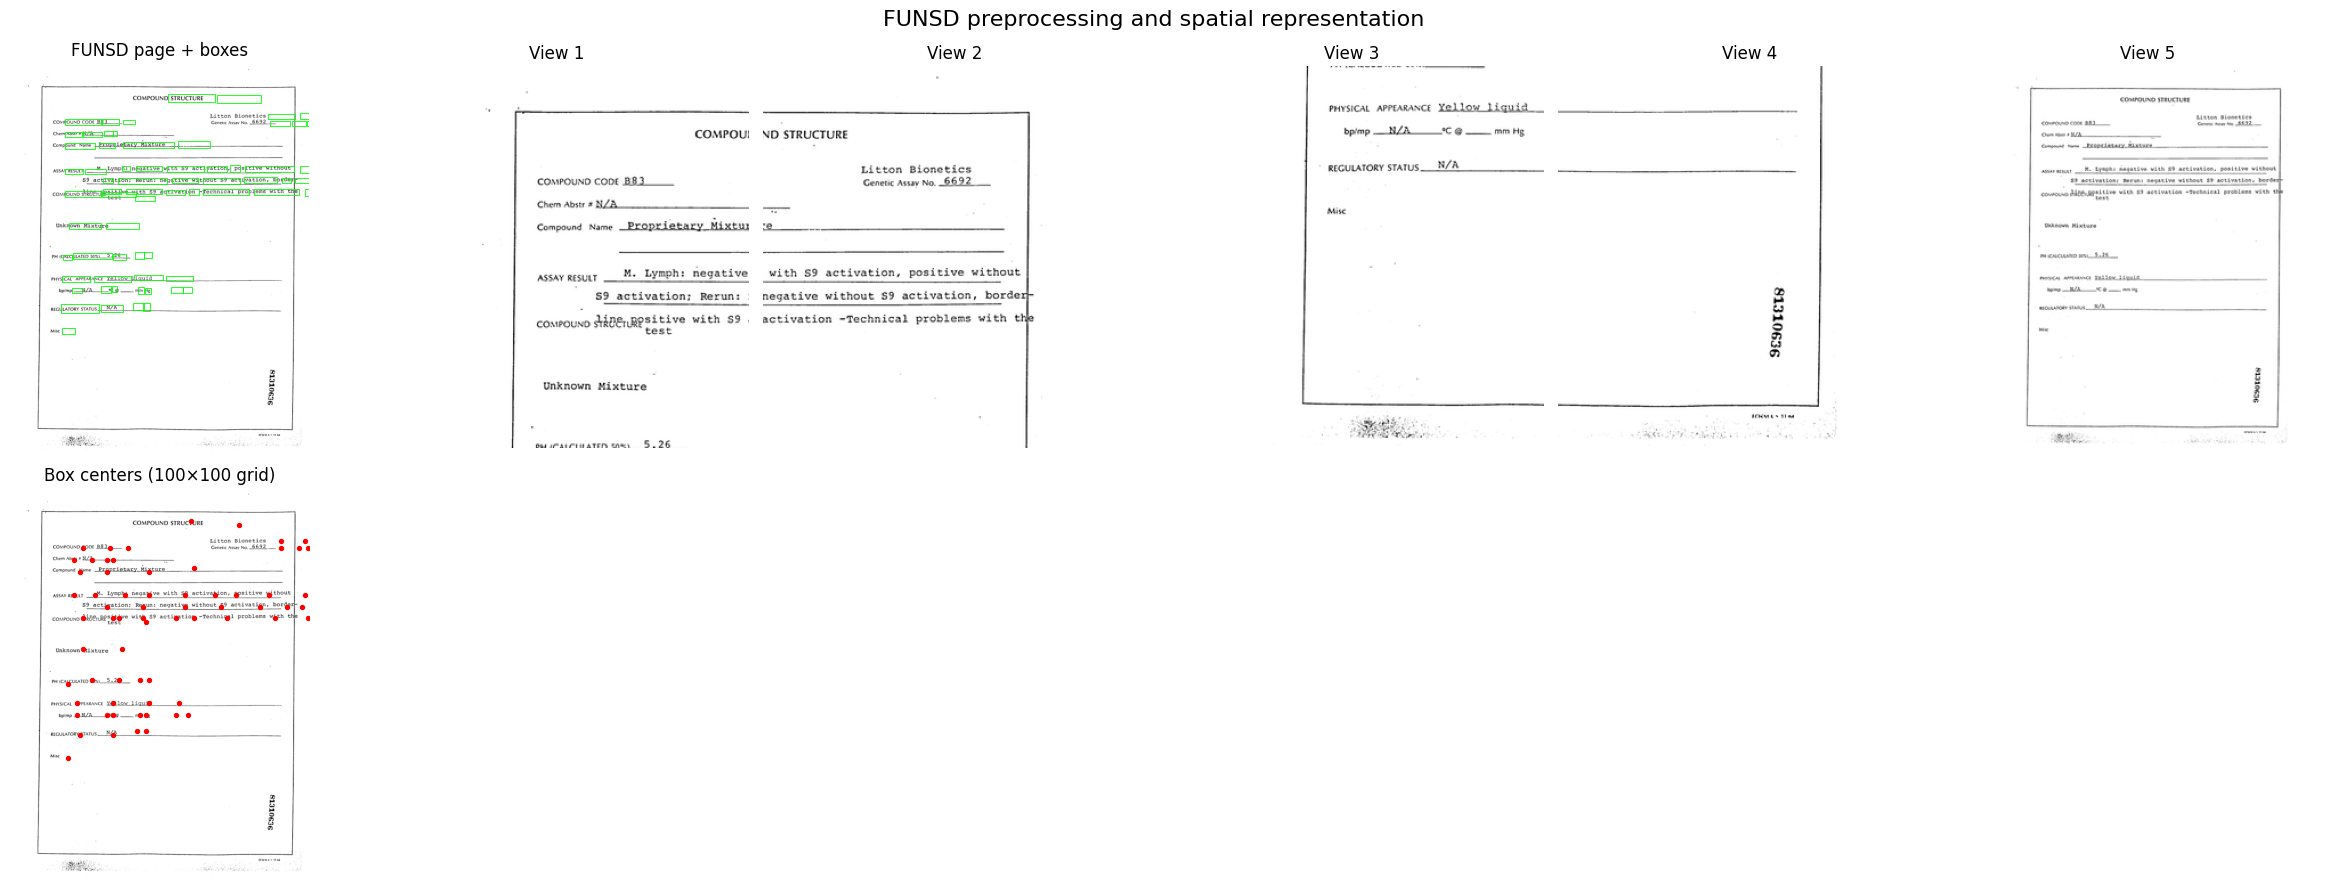

In [16]:
# Visualize one FUNSD document, its five crops, and normalized box centers.
from matplotlib.patches import Rectangle

visual_record = train_documents[0]
visual_image = _to_rgb_image(visual_record["image"])
visual_width, visual_height = visual_image.size

MESH_GRID_RESOLUTION = 100
visual_boxes = create_topological_mesh(
    visual_record["boxes"],
    visual_image.size,
    grid_resolution=MESH_GRID_RESOLUTION,
)
visual_crops = dynamic_crop_images(visual_image)

fig, axes = plt.subplots(2, 6, figsize=(24, 9))

# Original page with word boxes
axes[0, 0].imshow(visual_image)
axes[0, 0].set_title("FUNSD page + boxes")
for box in visual_record["boxes"]:
    x_min, x_max = min(box["x"]), max(box["x"])
    y_min, y_max = min(box["y"]), max(box["y"])
    axes[0, 0].add_patch(
        Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            fill=False,
            edgecolor="lime",
            linewidth=0.6,
        )
    )
axes[0, 0].axis("off")

# Five model views
for crop_index, crop in enumerate(visual_crops):
    axis = axes[0, crop_index + 1]
    axis.imshow(crop)
    axis.set_title(f"View {crop_index + 1}")
    axis.axis("off")

# Box centers mapped to the normalized spatial grid
axes[1, 0].imshow(visual_image)
axes[1, 0].set_title(f"Box centers ({MESH_GRID_RESOLUTION}×{MESH_GRID_RESOLUTION} grid)")

for box in visual_boxes:
    mesh_x = (box["col_idx"] + 0.5) / MESH_GRID_RESOLUTION * visual_width
    mesh_y = (box["row_idx"] + 0.5) / MESH_GRID_RESOLUTION * visual_height
    axes[1, 0].scatter(mesh_x, mesh_y, s=8, c="red")

axes[1, 0].set_xlim(0, visual_width)
axes[1, 0].set_ylim(visual_height, 0)
axes[1, 0].axis("off")

for axis in axes[1, 1:]:
    axis.axis("off")

fig.suptitle("FUNSD preprocessing and spatial representation", fontsize=16)
plt.tight_layout()
output_path = RESULTS_DIR / "dataset_visualizations.png"
plt.savefig(output_path, dpi=160, bbox_inches="tight")
print(f"Saved dataset visualizations to {output_path}")
plt.show()

## Step 3: Neural Network Assembly (The 5 Phases)

Phase 1: PatchProjector

In [17]:
# Phase 1: Multi-scale patch projector
EMBED_DIM = 128
PATCH_SIZE = 16


class PatchProjector(nn.Module):
    """Project image patches into a compact visual sequence."""

    def __init__(
        self,
        in_channels=3,
        patch_size=PATCH_SIZE,
        embed_dim=EMBED_DIM,
    ):
        super().__init__()

        if patch_size <= 0:
            raise ValueError("patch_size must be positive.")
        if embed_dim <= 0:
            raise ValueError("embed_dim must be positive.")

        self.in_channels = in_channels
        self.patch_size = patch_size
        self.embed_dim = embed_dim

        self.proj = nn.Conv2d(
            in_channels=in_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size,
        )

    def forward(self, x):
        # Expected shape: batch, views, channels, height, width
        if x.ndim != 5:
            raise ValueError(
                f"Expected images with shape [B, V, C, H, W]; got {tuple(x.shape)}."
            )

        batch_size, num_views, channels, height, width = x.shape

        if channels != self.in_channels:
            raise ValueError(
                f"Expected {self.in_channels} channels; got {channels}."
            )

        if height % self.patch_size != 0 or width % self.patch_size != 0:
            raise ValueError(
                f"Image size {(height, width)} must be divisible by "
                f"patch_size={self.patch_size}."
            )

        x = x.reshape(batch_size * num_views, channels, height, width)
        projected = self.proj(x)

        patches = projected.flatten(2).transpose(1, 2)
        return patches.reshape(batch_size, num_views * patches.shape[1], self.embed_dim)


print("Phase 1: PatchProjector implemented")

Phase 1: PatchProjector implemented


Phase 2: scale-invariant patch topology and local graph attention.

In [18]:
# Phase 2: scale-invariant patch topology and local graph attention.

class SpatialEmbedding(nn.Module):
    def __init__(self, embed_dim=EMBED_DIM, max_position=100):
        super().__init__()

        if embed_dim <= 0:
            raise ValueError("embed_dim must be positive.")
        if max_position <= 0:
            raise ValueError("max_position must be positive.")

        self.row_embedding = nn.Embedding(max_position, embed_dim)
        self.col_embedding = nn.Embedding(max_position, embed_dim)

    def forward(self, row_indices, col_indices):
        if row_indices.shape != col_indices.shape:
            raise ValueError(
                "row_indices and col_indices must have matching shapes."
            )

        row_indices = row_indices.long().clamp(
            0, self.row_embedding.num_embeddings - 1
        )
        col_indices = col_indices.long().clamp(
            0, self.col_embedding.num_embeddings - 1
        )

        return (
            self.row_embedding(row_indices) + self.col_embedding(col_indices)
        ) / 2


class LocalGraphAttention(nn.Module):
    """Apply attention over each patch and its four grid neighbors."""

    def __init__(self, embed_dim=EMBED_DIM, num_heads=4):
        super().__init__()

        if embed_dim <= 0:
            raise ValueError("embed_dim must be positive.")
        if num_heads <= 0 or embed_dim % num_heads != 0:
            raise ValueError(
                f"embed_dim ({embed_dim}) must be divisible by "
                f"num_heads ({num_heads})."
            )

        self.embed_dim = embed_dim
        self.norm = nn.LayerNorm(embed_dim)
        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            batch_first=True,
        )
        self.output = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 2),
            nn.GELU(),
            nn.Linear(embed_dim * 2, embed_dim),
        )

    def forward(self, patch_tokens, spatial_tokens, grid_height, grid_width):
        if patch_tokens.ndim != 3:
            raise ValueError("patch_tokens must have shape [B, N, D].")
        if spatial_tokens.shape != patch_tokens.shape:
            raise ValueError(
                "spatial_tokens must have the same shape as patch_tokens."
            )
        if patch_tokens.shape[-1] != self.embed_dim:
            raise ValueError(
                f"Expected embedding size {self.embed_dim}; "
                f"got {patch_tokens.shape[-1]}."
            )

        grid_height = int(grid_height)
        grid_width = int(grid_width)

        if grid_height <= 0 or grid_width <= 0:
            raise ValueError("Grid dimensions must be positive.")

        batch_size, token_count, embed_dim = patch_tokens.shape
        if token_count != grid_height * grid_width:
            raise ValueError(
                f"Token count {token_count} does not match grid "
                f"{grid_height} x {grid_width}."
            )

        sequence = patch_tokens + spatial_tokens

        # Arrange tokens into a 2D grid, then replicate the edges for padding.
        node_grid = sequence.transpose(1, 2).reshape(
            batch_size, embed_dim, grid_height, grid_width
        )
        padded = F.pad(node_grid, (1, 1, 1, 1), mode="replicate")

        # Neighbor order: up, down, left, right.
        neighborhood = torch.stack(
            [
                padded[:, :, 0:grid_height, 1:grid_width + 1],
                padded[:, :, 2:grid_height + 2, 1:grid_width + 1],
                padded[:, :, 1:grid_height + 1, 0:grid_width],
                padded[:, :, 1:grid_height + 1, 2:grid_width + 2],
            ],
            dim=1,
        )

        neighborhood = neighborhood.permute(0, 3, 4, 1, 2).reshape(
            batch_size * token_count, 4, embed_dim
        )
        query = self.norm(sequence).reshape(
            batch_size * token_count, 1, embed_dim
        )

        attended, _ = self.attention(
            query,
            neighborhood,
            neighborhood,
            need_weights=False,
        )
        attended = attended.reshape(batch_size, token_count, embed_dim)

        normalized = self.norm(sequence)
        return sequence + attended + self.output(normalized)


print("Phase 2: spatial embeddings and local four-neighbor attention ready")

Phase 2: spatial embeddings and local four-neighbor attention ready


Phase 3: linear-time bidirectional Mamba-style state-space processing.

In [19]:
# Phase 3: bidirectional state-space core.
# USE_REAL_MAMBA and _MambaBlock come from the earlier Mamba preflight cell.
SFBS_SEGMENT = None  # None = full-sequence scan; e.g. 49 enables segmented processing.

HAS_MAMBA_SSM = bool(
    torch.cuda.is_available()
    and globals().get("USE_REAL_MAMBA", False)
    and globals().get("_MambaBlock") is not None
)
USE_REAL_MAMBA = HAS_MAMBA_SSM

if not HAS_MAMBA_SSM:
    _MambaBlock = None


class EMAGatedBlock(nn.Module):
    """Fallback SSM-like block; this is not Mamba."""

    def __init__(self, dim=EMBED_DIM, expand_factor=2):
        super().__init__()

        if dim <= 0 or expand_factor <= 0:
            raise ValueError("dim and expand_factor must be positive.")

        expanded_dim = dim * expand_factor
        self.norm = nn.LayerNorm(dim)
        self.in_proj = nn.Linear(dim, expanded_dim * 2)
        self.state_proj = nn.Linear(expanded_dim, expanded_dim, bias=False)
        self.out_proj = nn.Linear(expanded_dim, dim)
        self.activation = nn.SiLU()
        self.decay = nn.Parameter(
            torch.full((expanded_dim,), 0.90).logit()
        )

    def _scan(self, u):
        if u.ndim != 3 or u.shape[1] == 0:
            raise ValueError("Expected a non-empty tensor with shape [B, N, D].")

        decay = torch.sigmoid(self.decay).to(
            device=u.device, dtype=u.dtype
        ).view(1, -1)

        state = torch.zeros_like(u[:, 0])
        outputs = []

        for step in range(u.shape[1]):
            state = decay * state + (1.0 - decay) * u[:, step]
            outputs.append(state)

        return torch.stack(outputs, dim=1)

    def forward(self, x):
        if x.ndim != 3 or x.shape[1] == 0:
            raise ValueError("Expected a non-empty tensor with shape [B, N, D].")

        values, gates = self.in_proj(self.norm(x)).chunk(2, dim=-1)
        u = self.state_proj(self.activation(values))

        forward_state = self._scan(u)
        backward_state = self._scan(u.flip(1)).flip(1)

        combined = (forward_state + backward_state) * torch.sigmoid(gates)
        return x + self.out_proj(combined)


class BiMambaBlock(nn.Module):
    """Bidirectional selective-scan Mamba block."""

    def __init__(self, dim=EMBED_DIM):
        super().__init__()

        if not HAS_MAMBA_SSM or _MambaBlock is None:
            raise RuntimeError(
                "BiMambaBlock requested, but the Mamba preflight did not pass."
            )

        self.norm = nn.LayerNorm(dim)
        self.fwd = _MambaBlock(
            d_model=dim, d_state=16, d_conv=4, expand=2
        )
        self.bwd = _MambaBlock(
            d_model=dim, d_state=16, d_conv=4, expand=2
        )
        self.out_proj = nn.Linear(2 * dim, dim)

    def forward(self, x):
        h = self.norm(x)
        forward = self.fwd(h)
        backward = self.bwd(h.flip(1)).flip(1)
        return x + self.out_proj(torch.cat([forward, backward], dim=-1))


def make_ssm_layer(dim=EMBED_DIM):
    if HAS_MAMBA_SSM:
        return BiMambaBlock(dim)
    return EMAGatedBlock(dim)


class BidirectionalMambaCore(nn.Module):
    """Stack bidirectional state-space layers over a visual token sequence."""

    def __init__(
        self,
        dim=EMBED_DIM,
        num_layers=4,
        segment_size=SFBS_SEGMENT,
    ):
        super().__init__()

        if num_layers <= 0:
            raise ValueError("num_layers must be positive.")
        if segment_size is not None and segment_size <= 0:
            raise ValueError("segment_size must be positive or None.")

        self.layers = nn.ModuleList(
            [make_ssm_layer(dim) for _ in range(num_layers)]
        )
        self.segment_size = segment_size
        self.cross = (
            nn.ModuleList(
                [make_ssm_layer(dim) for _ in range(num_layers)]
            )
            if segment_size is not None
            else None
        )
        self.norm = nn.LayerNorm(dim)

    def _sfbs(self, layer_index, layer, x):
        batch_size, sequence_length, dim = x.shape
        segment_size = self.segment_size

        if sequence_length == 0:
            raise ValueError("Cannot process an empty sequence.")

        # Require exact segments so padded tokens cannot affect the scan.
        if sequence_length % segment_size != 0:
            raise ValueError(
                f"Sequence length {sequence_length} must be divisible by "
                f"segment_size {segment_size} for SFBS."
            )

        num_segments = sequence_length // segment_size
        segments = x.reshape(
            batch_size * num_segments, segment_size, dim
        )
        scanned_segments = layer(segments)

        local_summary = scanned_segments.mean(dim=1).reshape(
            batch_size, num_segments, dim
        )
        global_summary = self.cross[layer_index](local_summary)

        adjusted_segments = scanned_segments + (
            global_summary - local_summary
        ).reshape(batch_size * num_segments, 1, dim)

        return adjusted_segments.reshape(
            batch_size, sequence_length, dim
        )

    def forward(self, x):
        if x.ndim != 3 or x.shape[1] == 0:
            raise ValueError("Expected a non-empty tensor with shape [B, N, D].")

        for index, layer in enumerate(self.layers):
            if self.segment_size is None:
                x = layer(x)
            else:
                x = self._sfbs(index, layer, x)

        return self.norm(x)


implementation = (
    "REAL Mamba (preflight passed)"
    if USE_REAL_MAMBA
    else "EMA fallback (not Mamba; Python scan may be slow)"
)
print(f"Phase 3: {implementation}; SFBS segment = {SFBS_SEGMENT}")

Phase 3: EMA fallback (not Mamba; Python scan may be slow); SFBS segment = None


Phase 4: Dimension alignment into the pretrained decoder hidden space

In [20]:
# Phase 4: align visual features to the decoder hidden size and pool visual tokens.

LLM_HIDDEN_SIZE = 768
MAX_PREFIX_TOKENS = 700  # Leaves room in distilgpt2's 1024-token context for prompt and output.


class DimensionAlignmentMLP(nn.Module):
    def __init__(
        self,
        input_dim=EMBED_DIM,
        hidden_dim=256,
        output_dim=LLM_HIDDEN_SIZE,
    ):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x):
        if x.shape[-1] != self.net[0].in_features:
            raise ValueError(
                f"Expected input feature size {self.net[0].in_features}, "
                f"got {x.shape[-1]}."
            )
        return self.net(x)


def pool_visual(x, views, grid, max_tokens=MAX_PREFIX_TOKENS):
    """
    Pool a visual sequence from (B, views * grid * grid, D) to at most
    max_tokens, preserving the view and spatial-grid structure.
    """
    if x.ndim != 3:
        raise ValueError(f"Expected x with shape (B, N, D); got {tuple(x.shape)}.")
    if views <= 0 or grid <= 0 or max_tokens <= 0:
        raise ValueError("views, grid, and max_tokens must all be positive.")

    batch_size, token_count, embed_dim = x.shape
    expected_tokens = views * grid * grid
    if token_count != expected_tokens:
        raise ValueError(
            f"Expected {expected_tokens} tokens for {views} views on a "
            f"{grid}x{grid} grid; got {token_count}."
        )

    # Find the smallest pooling kernel that fits within the token budget.
    kernel = 1
    while views * ((grid + kernel - 1) // kernel) ** 2 > max_tokens:
        kernel += 1

    feature_map = (
        x.reshape(batch_size * views, grid, grid, embed_dim)
         .permute(0, 3, 1, 2)
    )

    if kernel > 1:
        feature_map = F.avg_pool2d(
            feature_map,
            kernel_size=kernel,
            stride=kernel,
            ceil_mode=True,
            count_include_pad=False,
        )

    pooled = feature_map.flatten(2).transpose(1, 2)
    pooled = pooled.reshape(batch_size, -1, embed_dim)

    if pooled.shape[1] > max_tokens:
        raise RuntimeError(
            f"Pooling produced {pooled.shape[1]} tokens, exceeding limit "
            f"{max_tokens}."
        )

    return pooled


print("Phase 4: dimension alignment and adaptive visual-token pooling ready.")

Phase 4: dimension alignment and adaptive visual-token pooling ready.


Phase 5: pretrained causal decoder with optional 4-bit QLoRA visual-prefix conditioning.


In [21]:
# Phase 5: pretrained causal decoder with LoRA and visual-prefix conditioning.

from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

LLM_MODEL_NAME = os.environ.get("OMNIDOC_LLM", "distilgpt2")
USE_4BIT_QLORA = (
    os.environ.get("OMNIDOC_4BIT", "0") == "1"
    and torch.cuda.is_available()
)

GEN_NO_REPEAT = 3
GEN_REP_PENALTY = 1.2


class QLoRAAdapter(nn.Module):
    """Pretrained causal LM with LoRA and a projected visual prefix."""

    def __init__(
        self,
        base_model_name=LLM_MODEL_NAME,
        lora_rank=16,
        lora_alpha=32,
        lora_dropout=0.05,
    ):
        super().__init__()

        load_kwargs = {}
        if USE_4BIT_QLORA:
            load_kwargs = {
                "quantization_config": BitsAndBytesConfig(
                    load_in_4bit=True,
                    bnb_4bit_quant_type="nf4",
                    bnb_4bit_compute_dtype=torch.float16,
                    bnb_4bit_use_double_quant=True,
                ),
                "device_map": {"": torch.cuda.current_device()},
            }

        # Fail visibly if model loading or LoRA setup fails. Do not silently
        # substitute randomly initialized weights for the pretrained decoder.
        base = AutoModelForCausalLM.from_pretrained(
            base_model_name,
            **load_kwargs,
        )

        if USE_4BIT_QLORA:
            base = prepare_model_for_kbit_training(base)

        model_type = getattr(base.config, "model_type", "")
        if model_type == "gpt2":
            target_modules = ["c_attn", "c_proj", "c_fc"]
            fan_in_fan_out = True  # GPT-2 uses Conv1D layers.
        else:
            target_modules = ["q_proj", "k_proj", "v_proj", "o_proj"]
            fan_in_fan_out = False

        lora_config = LoraConfig(
            r=lora_rank,
            lora_alpha=lora_alpha,
            lora_dropout=lora_dropout,
            target_modules=target_modules,
            fan_in_fan_out=fan_in_fan_out,
            task_type="CAUSAL_LM",
        )

        self.model = get_peft_model(base, lora_config)
        self.hidden_size = int(base.config.hidden_size)
        self.input_embeddings = self.model.get_input_embeddings()
        self.visual_projection = nn.Linear(LLM_HIDDEN_SIZE, self.hidden_size)

        if hasattr(self.model.config, "use_cache"):
            self.model.config.use_cache = False

        self.is_hf = True

    def forward(self, input_ids, attention_mask, visual_prefix):
        """
        Return causal-LM logits at text positions: (batch, text_length, vocab).
        """
        if input_ids.ndim != 2 or attention_mask.shape != input_ids.shape:
            raise ValueError("input_ids and attention_mask must have matching (B, T) shapes.")
        if visual_prefix.ndim != 3:
            raise ValueError("visual_prefix must have shape (B, visual_tokens, hidden_size).")
        if visual_prefix.shape[0] != input_ids.shape[0]:
            raise ValueError("Visual-prefix and text batch sizes do not match.")
        if visual_prefix.shape[-1] != LLM_HIDDEN_SIZE:
            raise ValueError(
                f"Expected visual-prefix size {LLM_HIDDEN_SIZE}; "
                f"got {visual_prefix.shape[-1]}."
            )

        visual = self.visual_projection(visual_prefix)
        text_embeddings = self.input_embeddings(input_ids)

        # Match the decoder embedding dtype (important for half/4-bit runs).
        visual = visual.to(device=text_embeddings.device, dtype=text_embeddings.dtype)
        attention_mask = attention_mask.to(text_embeddings.device)

        embeddings = torch.cat([visual, text_embeddings], dim=1)
        prefix_mask = torch.ones(
            visual.shape[:2],
            dtype=attention_mask.dtype,
            device=attention_mask.device,
        )
        combined_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        outputs = self.model(
            inputs_embeds=embeddings,
            attention_mask=combined_mask,
            use_cache=False,
        )
        return outputs.logits[:, visual.shape[1]:, :]

    @torch.no_grad()
    def generate(
        self,
        input_ids,
        attention_mask,
        visual_prefix,
        tokenizer,
        max_new_tokens=128,
    ):
        visual = self.visual_projection(visual_prefix)
        text_embeddings = self.input_embeddings(input_ids)
        visual = visual.to(device=text_embeddings.device, dtype=text_embeddings.dtype)
        attention_mask = attention_mask.to(text_embeddings.device)

        embeddings = torch.cat([visual, text_embeddings], dim=1)
        prefix_mask = torch.ones(
            visual.shape[:2],
            dtype=attention_mask.dtype,
            device=attention_mask.device,
        )
        combined_mask = torch.cat([prefix_mask, attention_mask], dim=1)

        generated = self.model.generate(
            inputs_embeds=embeddings,
            attention_mask=combined_mask,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            no_repeat_ngram_size=GEN_NO_REPEAT,
            repetition_penalty=GEN_REP_PENALTY,
            pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

        return tokenizer.decode(
            generated[0].tolist(),
            skip_special_tokens=True,
        ).strip()


print(
    f"Phase 5: pretrained decoder ready ({LLM_MODEL_NAME}); "
    f"LoRA enabled; 4-bit={USE_4BIT_QLORA}"
)

Phase 5: pretrained decoder ready (distilgpt2); LoRA enabled; 4-bit=False


OmniDoc-Mamba v2 model.

In [22]:
# Complete OmniDoc-Mamba v3 model.

class OmniDocMambaV2(nn.Module):
    """
    OCR-free visual document model:
    patch projector + local graph attention + bidirectional sequence core
    + prompt gate + LoRA-adapted causal decoder.
    """

    def __init__(self, embed_dim=EMBED_DIM, llm_model=LLM_MODEL_NAME):
        super().__init__()

        self.patch_projector = PatchProjector(embed_dim=embed_dim)
        self.spatial_embedding = SpatialEmbedding(embed_dim=embed_dim)
        self.graph_attention = LocalGraphAttention(embed_dim=embed_dim)
        self.mamba_core = BidirectionalMambaCore(dim=embed_dim, num_layers=4)

        self.alignment_mlp = DimensionAlignmentMLP(
            input_dim=embed_dim,
            output_dim=LLM_HIDDEN_SIZE,
        )
        self.decoder = QLoRAAdapter(base_model_name=llm_model)
        self.prompt_gate = nn.Sequential(
            nn.Linear(self.decoder.hidden_size, embed_dim),
            nn.Sigmoid(),
        )

        # Set with configure_prompt() before training.
        self.prompt_len = None

        self.reconstruction_head = nn.Linear(
            embed_dim,
            3 * PATCH_SIZE * PATCH_SIZE,
        )
        self.mask_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        nn.init.normal_(self.mask_token, std=0.02)

    def configure_prompt(self, tokenizer, prompt_text=PROMPT_TEXT):
        """Record the prompt token count so training never gates on answer tokens."""
        prompt_ids = tokenizer(
            prompt_text,
            add_special_tokens=False,
        )["input_ids"]

        if not prompt_ids:
            raise ValueError("The configured prompt tokenized to an empty sequence.")

        self.prompt_len = len(prompt_ids)
        return self.prompt_len

    def _prompt_context(self, input_ids, attention_mask=None, allow_full_prompt=False):
        """
        Return mean prompt embedding, shape (B, H).

        Training requires a configured prompt length, preventing answer-token
        leakage. Inference may use the entire supplied prompt.
        """
        if self.prompt_len is None and not allow_full_prompt:
            raise RuntimeError(
                "Prompt length is not configured. Call "
                "model.configure_prompt(tokenizer, PROMPT_TEXT) before training."
            )

        embeddings = self.decoder.input_embeddings(input_ids)

        if self.prompt_len is not None:
            embeddings = embeddings[:, :self.prompt_len]
            if attention_mask is not None:
                weights = attention_mask[:, :self.prompt_len].to(embeddings.dtype)
            else:
                weights = torch.ones(
                    embeddings.shape[:2],
                    dtype=embeddings.dtype,
                    device=embeddings.device,
                )
        else:
            # Inference only: input_ids contain the prompt, not the answer.
            if attention_mask is None:
                weights = torch.ones(
                    embeddings.shape[:2],
                    dtype=embeddings.dtype,
                    device=embeddings.device,
                )
            else:
                weights = attention_mask.to(embeddings.dtype)

        weights = weights.unsqueeze(-1)
        return (embeddings * weights).sum(dim=1) / weights.sum(dim=1).clamp_min(1)

    def forward_visual(
        self,
        images,
        prompt_context=None,
        patch_mask=None,
    ):
        if images.ndim != 5:
            raise ValueError(
                f"Expected images shaped (B, views, C, H, W); got {tuple(images.shape)}."
            )

        batch_size, num_views, _, image_height, image_width = images.shape
        if image_height % PATCH_SIZE or image_width % PATCH_SIZE:
            raise ValueError(
                f"Image dimensions {(image_height, image_width)} must be divisible "
                f"by PATCH_SIZE={PATCH_SIZE}."
            )

        patch_height = image_height // PATCH_SIZE
        patch_width = image_width // PATCH_SIZE
        tokens_per_view = patch_height * patch_width

        visual_seq = self.patch_projector(images)

        if patch_mask is not None:
            if patch_mask.shape != visual_seq.shape[:2]:
                raise ValueError(
                    f"patch_mask must have shape {tuple(visual_seq.shape[:2])}; "
                    f"got {tuple(patch_mask.shape)}."
                )
            mask_token = self.mask_token.to(
                device=visual_seq.device,
                dtype=visual_seq.dtype,
            ).expand_as(visual_seq)
            visual_seq = torch.where(
                patch_mask.to(device=visual_seq.device, dtype=torch.bool).unsqueeze(-1),
                mask_token,
                visual_seq,
            )

        rows = torch.arange(
            patch_height, device=images.device
        ).repeat_interleave(patch_width)
        cols = torch.arange(
            patch_width, device=images.device
        ).repeat(patch_height)

        patch_rows = rows.unsqueeze(0).expand(batch_size * num_views, -1)
        patch_cols = cols.unsqueeze(0).expand(batch_size * num_views, -1)
        spatial_tokens = self.spatial_embedding(patch_rows, patch_cols)

        per_view_tokens = visual_seq.reshape(
            batch_size * num_views,
            tokens_per_view,
            -1,
        )
        per_view_tokens = self.graph_attention(
            per_view_tokens,
            spatial_tokens,
            patch_height,
            patch_width,
        )

        visual_seq = per_view_tokens.reshape(
            batch_size,
            num_views * tokens_per_view,
            -1,
        )
        state_space = self.mamba_core(visual_seq)

        if prompt_context is not None:
            gate = self.prompt_gate(prompt_context).unsqueeze(1)
            state_space = state_space * gate

        return state_space

    def visual_prefix(self, state_space, images):
        if images.shape[-2] != images.shape[-1]:
            raise ValueError("visual_prefix currently expects square image views.")

        views = images.shape[1]
        grid = images.shape[-1] // PATCH_SIZE

        pooled = pool_visual(
            state_space,
            views=views,
            grid=grid,
            max_tokens=MAX_PREFIX_TOKENS,
        )
        return self.alignment_mlp(pooled)

    def forward(
        self,
        images,
        row_indices,
        col_indices,
        input_ids,
        attention_mask=None,
    ):
        # row_indices/col_indices are retained for compatibility with the
        # existing training loop. The encoder currently builds spatial
        # embeddings from the image patch grid and does not consume these
        # document-word mesh indices.
        del row_indices, col_indices

        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids)

        # Strictly uses the configured prompt prefix, never answer tokens.
        context = self._prompt_context(input_ids, attention_mask)
        state_space = self.forward_visual(images, prompt_context=context)
        prefix = self.visual_prefix(state_space, images)

        return self.decoder(input_ids, attention_mask, prefix)

    @torch.no_grad()
    def generate_text(
        self,
        images,
        prompt,
        tokenizer,
        device,
        max_new_tokens=128,
    ):
        was_training = self.training
        self.eval()

        try:
            prompt_tokens = tokenizer(
                prompt,
                return_tensors="pt",
                truncation=True,
                max_length=128,
            )
            input_ids = prompt_tokens["input_ids"].to(device)
            attention_mask = prompt_tokens["attention_mask"].to(device)

            context = self._prompt_context(
                input_ids,
                attention_mask,
                allow_full_prompt=True,
            )
            images = images.to(device)
            state_space = self.forward_visual(images, prompt_context=context)
            prefix = self.visual_prefix(state_space, images)

            return self.decoder.generate(
                input_ids,
                attention_mask,
                prefix,
                tokenizer,
                max_new_tokens=max_new_tokens,
            )
        finally:
            self.train(was_training)


print("OmniDoc-Mamba model class implemented.")
print("Before training, run: model.configure_prompt(tokenizer, PROMPT_TEXT)")

OmniDoc-Mamba model class implemented.
Before training, run: model.configure_prompt(tokenizer, PROMPT_TEXT)


In [23]:
# Load the decoder tokenizer and create the model.
tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_NAME)

# GPT-2 tokenizers do not define a separate padding token.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = OmniDocMambaV2()
model.to(device)
model.configure_prompt(tokenizer, PROMPT_TEXT)

print("Model created on:", device)
print("Prompt length:", model.prompt_len)

/csehome/m25mac003/venvs/omnidoc/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Model created on: cuda
Prompt length: 6


In [24]:
model.configure_prompt(tokenizer, PROMPT_TEXT)

6

## Step 4: Two-Stage Training Protocol

In [25]:
# Load the tokenizer that matches the pretrained decoder.
tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_NAME)

# GPT-2 tokenizers have no separate padding token; reuse EOS.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

# Make sure tokenizer IDs fit the decoder's embedding table.
embedding_count = model.decoder.input_embeddings.num_embeddings
if len(tokenizer) > embedding_count:
    raise ValueError(
        f"Tokenizer has {len(tokenizer)} tokens, but decoder embeddings support "
        f"only {embedding_count}. Use the tokenizer matching {LLM_MODEL_NAME}."
    )

# Refresh the prompt length on the model already created.
PROMPT_IDS = tokenizer(PROMPT_TEXT, add_special_tokens=False)["input_ids"]
PROMPT_LEN = len(PROMPT_IDS)
model.configure_prompt(tokenizer, PROMPT_TEXT)

print(f"Tokenizer loaded: {LLM_MODEL_NAME}")
print(f"Tokenizer size: {len(tokenizer)} | Decoder embedding rows: {embedding_count}")
print(f"Prompt: {PROMPT_TEXT!r} -> {PROMPT_LEN} tokens")

Tokenizer loaded: distilgpt2
Tokenizer size: 50257 | Decoder embedding rows: 50257
Prompt: 'Extract the document text:' -> 6 tokens


In [26]:
# Reuse the current model, or initialize it if this is the first run.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

if "model" not in globals() or not isinstance(model, OmniDocMambaV2):
    model = OmniDocMambaV2(
        embed_dim=EMBED_DIM,
        llm_model=LLM_MODEL_NAME,
    )

    if USE_4BIT_QLORA:
        # Keep the quantized decoder in its assigned device; move visual modules.
        model.patch_projector.to(device)
        model.spatial_embedding.to(device)
        model.graph_attention.to(device)
        model.mamba_core.to(device)
        model.alignment_mlp.to(device)
        model.reconstruction_head.to(device)
        model.prompt_gate.to(device)
        model.mask_token.data = model.mask_token.data.to(device)
        model.decoder.visual_projection.to(device)
    else:
        model.to(device)
else:
    print("Reusing the model already in memory.")

model.configure_prompt(tokenizer, PROMPT_TEXT)

total_parameters = sum(p.numel() for p in model.parameters())
trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Model ready")
print(f"  Total parameters: {total_parameters:,}")
print(f"  Trainable parameters: {trainable_parameters:,}")
print(f"  Prompt tokens: {model.prompt_len}")
print(f"  Real Mamba enabled: {USE_REAL_MAMBA}")

Device: cuda
Reusing the model already in memory.
Model ready
  Total parameters: 85,027,328
  Trainable parameters: 3,114,752
  Prompt tokens: 6
  Real Mamba enabled: False


In [27]:
# Build train / dev / official test dataloaders.
# Use the official test loader only for final reporting.

if not train_documents:
    raise ValueError("Training split is empty. Check the FUNSD download and split cells.")
if not dev_documents:
    raise ValueError("Dev split is empty. Check that the training split has enough documents.")
if not validation_documents:
    raise ValueError("Official test split is empty. Check the FUNSD download cell.")

train_dataset = DocumentDataset(
    train_documents, tokenizer, max_seq_len=128, task="kie"
)
dev_dataset = DocumentDataset(
    dev_documents, tokenizer, max_seq_len=128, task="kie"
)
validation_dataset = DocumentDataset(
    validation_documents, tokenizer, max_seq_len=128, task="kie"
)

BATCH_SIZE = int(
    os.environ.get(
        "OMNIDOC_BATCH_SIZE",
        2 if torch.cuda.is_available() else 1,
    )
)
# Start with no worker subprocesses; increase after the first batches work.
NUM_WORKERS = int(os.environ.get("OMNIDOC_WORKERS", 0))

if BATCH_SIZE < 1 or NUM_WORKERS < 0:
    raise ValueError("BATCH_SIZE must be >= 1 and NUM_WORKERS must be >= 0.")

_loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
    "persistent_workers": NUM_WORKERS > 0,
}

_loader_generator = torch.Generator()
_loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=_loader_generator,
    **_loader_kwargs,
)
dev_loader = DataLoader(
    dev_dataset,
    shuffle=False,
    **_loader_kwargs,
)
validation_loader = DataLoader(
    validation_dataset,
    shuffle=False,
    **_loader_kwargs,
)

print("Dataloaders created")
print(
    f"  Train: {len(train_dataset)} | "
    f"Dev: {len(dev_dataset)} | "
    f"Test: {len(validation_dataset)}"
)
print(
    f"  Batch size: {BATCH_SIZE} | Workers: {NUM_WORKERS} | "
    f"Train batches: {len(train_loader)}"
)
print("  Keep validation_loader for final test reporting only.")

Dataloaders created
  Train: 134 | Dev: 15 | Test: 50
  Batch size: 2 | Workers: 0 | Train batches: 67
  Keep validation_loader for final test reporting only.


In [28]:
# Stage A: masked patch modeling.
# Masked patches are replaced before the visual encoder processes them.

def pretrain_step(model, batch, device, mask_ratio=0.5):
    if not 0.0 <= mask_ratio <= 1.0:
        raise ValueError("mask_ratio must be between 0 and 1.")

    images = batch["images"].to(device, non_blocking=True)
    if images.ndim != 5:
        raise ValueError(
            f"Expected images shaped (B, V, C, H, W); got {tuple(images.shape)}."
        )

    batch_size, num_views, channels, height, width = images.shape
    if height % PATCH_SIZE or width % PATCH_SIZE:
        raise ValueError(f"Image dimensions must be divisible by PATCH_SIZE={PATCH_SIZE}.")

    # Ground-truth RGB patches, in the same B / view / patch order as the encoder.
    targets = F.unfold(
        images.reshape(batch_size * num_views, channels, height, width),
        kernel_size=PATCH_SIZE,
        stride=PATCH_SIZE,
    )
    targets = targets.transpose(1, 2).reshape(
        batch_size,
        -1,
        channels * PATCH_SIZE * PATCH_SIZE,
    )

    # Skip nearly blank patches, which carry little reconstruction signal.
    ink = targets.std(dim=-1, unbiased=False) > 0.02
    if not ink.any():
        # Differentiable zero so a training loop can still call backward().
        return model.reconstruction_head.weight.sum() * 0.0

    patch_mean = targets.mean(dim=-1, keepdim=True)
    patch_std = targets.std(dim=-1, keepdim=True, unbiased=False).clamp_min(1e-6)
    normalized_targets = (targets - patch_mean) / patch_std

    mask = (torch.rand(ink.shape, device=device) < mask_ratio) & ink
    if not mask.any():
        # Ensure at least one informative patch is masked.
        candidates = torch.nonzero(ink, as_tuple=False)
        chosen = candidates[torch.randint(len(candidates), (1,), device=device)].squeeze(0)
        mask[chosen[0], chosen[1]] = True

    prompt_ids = torch.tensor(
        PROMPT_IDS,
        dtype=torch.long,
        device=device,
    ).unsqueeze(0).expand(batch_size, -1)

    # These IDs contain only the prompt, never the target answer.
    context = model._prompt_context(prompt_ids, allow_full_prompt=True)

    encoded = model.forward_visual(
        images,
        prompt_context=context,
        patch_mask=mask,
    )
    predictions = model.reconstruction_head(encoded)

    if predictions.shape != normalized_targets.shape:
        raise RuntimeError(
            f"Prediction shape {tuple(predictions.shape)} does not match target "
            f"shape {tuple(normalized_targets.shape)}."
        )

    return F.mse_loss(
        predictions[mask].float(),
        normalized_targets[mask].float(),
    )


print("Masked patch modeling step defined")

Masked patch modeling step defined


In [29]:
# Stage B: supervised causal fine-tuning on FUNSD text targets.

def finetune_step(model, batch, device):
    images = batch["images"].to(device, non_blocking=True)
    row_indices = batch["row_indices"].to(device, non_blocking=True)
    col_indices = batch["col_indices"].to(device, non_blocking=True)
    input_ids = batch["input_ids"].to(device, non_blocking=True)
    attention_mask = batch["attention_mask"].to(device, non_blocking=True)
    labels = batch["labels"].to(device, non_blocking=True)

    if input_ids.shape != labels.shape or input_ids.shape != attention_mask.shape:
        raise ValueError("input_ids, labels, and attention_mask must have matching shapes.")

    logits = model(
        images,
        row_indices,
        col_indices,
        input_ids,
        attention_mask,
    )

    # Causal next-token prediction: logits at t predict labels at t+1.
    shifted_logits = logits[:, :-1, :].contiguous()
    shifted_labels = labels[:, 1:].contiguous()

    valid_tokens = shifted_labels.ne(-100)
    if not valid_tokens.any():
        raise ValueError(
            "This batch has no supervised target tokens. Check prompt masking "
            "and max_seq_len in DocumentDataset."
        )

    return F.cross_entropy(
        shifted_logits.view(-1, shifted_logits.shape[-1]),
        shifted_labels.view(-1),
        ignore_index=-100,
    )


print("Supervised fine-tuning step defined")

Supervised fine-tuning step defined


In [30]:
# Research-training configuration: separate optimizer and schedule per stage.

from torch.optim.lr_scheduler import LinearLR, SequentialLR

NUM_PRETRAIN_EPOCHS = 5
NUM_FINETUNE_EPOCHS = 15
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01
GRADIENT_CLIP_NORM = 1.0
PATIENCE = 4


def make_optimizer(epochs, steps_per_epoch=None):
    if epochs < 1:
        raise ValueError("epochs must be at least 1.")

    if steps_per_epoch is None:
        steps_per_epoch = len(train_loader)
    if steps_per_epoch < 1:
        raise ValueError("Training loader has no batches.")

    parameters = [p for p in model.parameters() if p.requires_grad]
    if not parameters:
        raise ValueError("The model has no trainable parameters.")

    optimizer = AdamW(
        parameters,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    total_steps = steps_per_epoch * epochs
    if total_steps < 2:
        raise ValueError(
            f"Need at least 2 optimizer steps for warmup/cosine scheduling; "
            f"got {total_steps}."
        )

    warmup_steps = min(max(1, round(0.05 * total_steps)), total_steps - 1)

    warmup_scheduler = LinearLR(
        optimizer,
        start_factor=0.1,
        end_factor=1.0,
        total_iters=warmup_steps,
    )
    cosine_scheduler = CosineAnnealingLR(
        optimizer,
        T_max=total_steps - warmup_steps,
        eta_min=0.0,
    )
    scheduler = SequentialLR(
        optimizer,
        schedulers=[warmup_scheduler, cosine_scheduler],
        milestones=[warmup_steps],
    )

    return optimizer, scheduler


# PyTorch 2.1-compatible CUDA gradient scaler.
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

print("Research-training configuration ready")
print(
    f"  Pretraining epochs: {NUM_PRETRAIN_EPOCHS} | "
    f"Fine-tuning epochs: {NUM_FINETUNE_EPOCHS} "
    f"(early-stop patience {PATIENCE})"
)
print(
    "  Trainable parameters: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

Research-training configuration ready
  Pretraining epochs: 5 | Fine-tuning epochs: 15 (early-stop patience 4)
  Trainable parameters: 3,114,752


In [31]:
# Stage A: masked-patch reconstruction pretraining.
# Requires a live CUDA GPU allocation.

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable in this notebook kernel. Reconnect to the "
        "GPU-backed cluster kernel before running Stage A."
    )

device = torch.device("cuda")
model_device = next(model.patch_projector.parameters()).device
if model_device.type != "cuda":
    raise RuntimeError(
        f"The model is on {model_device}. Rerun model initialization in the "
        "GPU-backed kernel before training."
    )

print(f"GPU: {torch.cuda.get_device_name(0)}")

print("\n" + "=" * 70)
print("STAGE A: MASKED PATCH MODELING")
print("=" * 70)

optimizer, scheduler = make_optimizer(NUM_PRETRAIN_EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=True)

model.train()
pretrain_losses = []

for epoch in range(NUM_PRETRAIN_EPOCHS):
    epoch_loss = 0.0
    batch_count = 0
    progress = tqdm(
        train_loader,
        desc=f"Pretrain {epoch + 1}/{NUM_PRETRAIN_EPOCHS}",
    )

    for batch in progress:
        optimizer.zero_grad(set_to_none=True)

        # Create CUDA autocast only after confirming CUDA is available.
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = pretrain_step(model, batch, device)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite pretraining loss: {loss.item()}")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            [
                p for p in model.parameters()
                if p.requires_grad and p.grad is not None
            ],
            GRADIENT_CLIP_NORM,
        )

        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()

        # GradScaler reduces its scale if it skips an optimizer update.
        if scaler.get_scale() >= old_scale:
            scheduler.step()

        loss_value = float(loss.detach().float().cpu())
        epoch_loss += loss_value
        batch_count += 1
        pretrain_losses.append(loss_value)
        progress.set_postfix(loss=f"{loss_value:.4f}")

    if batch_count == 0:
        raise RuntimeError("Training loader yielded no batches.")

    checkpoint_path = MODELS_DIR / f"pretrain_epoch_{epoch + 1}.pt"
    torch.save(model.state_dict(), checkpoint_path)

    mean_loss = epoch_loss / batch_count
    print(f"Epoch {epoch + 1}: normalized masked-patch loss = {mean_loss:.4f}")
    print(f"Saved checkpoint: {checkpoint_path}")

print("Stage A pretraining completed.")

GPU: NVIDIA A30

STAGE A: MASKED PATCH MODELING


Pretrain 1/5:   0%|          | 0/67 [00:00<?, ?it/s]

/opt/ohpc/apps/python/3.10.pytorch/lib/python3.10/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:80.)
  return F.conv2d(input, weight, bias, self.stride,


Epoch 1: normalized masked-patch loss = 1.0271
Saved checkpoint: /scratch/m25mac003/omnidoc_outputs/models/pretrain_epoch_1.pt


Pretrain 2/5:   0%|          | 0/67 [00:00<?, ?it/s]

Epoch 2: normalized masked-patch loss = 1.0001
Saved checkpoint: /scratch/m25mac003/omnidoc_outputs/models/pretrain_epoch_2.pt


... (2 outputs left out)

Pretrain 4/5:   0%|          | 0/67 [00:00<?, ?it/s]

Epoch 4: normalized masked-patch loss = 0.9994
Saved checkpoint: /scratch/m25mac003/omnidoc_outputs/models/pretrain_epoch_4.pt


Pretrain 5/5:   0%|          | 0/67 [00:00<?, ?it/s]

Epoch 5: normalized masked-patch loss = 0.9994
Saved checkpoint: /scratch/m25mac003/omnidoc_outputs/models/pretrain_epoch_5.pt
Stage A pretraining completed.


## Stage A2: synthetic reading pretraining (the actual fix for the collapse)
Rendered pages with **known text in reading order**, same prompt, same model path and same loss as FUNSD fine-tuning. Watch the **synthetic CER** printed every epoch: it must fall well below 1.0. If it stays at about 1.0, the model cannot read even clean rendered text and no amount of FUNSD training will fix that.

In [32]:
# Synthetic reading data: rendered pages with known reading-order targets.
import matplotlib.font_manager as fm
from PIL import ImageDraw, ImageFont, ImageFilter

try:
    SYN_FONT_PATH = fm.findfont("DejaVu Sans", fallback_to_default=True)
    if not Path(SYN_FONT_PATH).is_file():
        raise FileNotFoundError(SYN_FONT_PATH)
except Exception as error:
    raise RuntimeError(
        "Could not find a usable font on this cluster. "
        "Set SYN_FONT_PATH to an installed .ttf font file."
    ) from error


def build_vocab(documents, max_words=20_000):
    words = []
    for document in documents:
        for word in document.get("values", []) or []:
            if isinstance(word, str) and word.strip():
                words.append(word.strip())

    return list(dict.fromkeys(words))[:max_words] or ["field", "value"]


def render_synthetic_page(vocab, rng, max_words=30):
    if not vocab:
        vocab = ["field", "value"]
    if max_words < 1:
        raise ValueError("max_words must be at least 1.")

    width = rng.randint(650, 800)
    height = rng.randint(850, 1050)
    shade = rng.randint(232, 255)

    page = Image.new("RGB", (width, height), (shade, shade, shade))
    draw = ImageDraw.Draw(page)
    boxes, values = [], []
    y = rng.randint(15, 60)

    while y < height - 40 and len(values) < max_words:
        size = rng.randint(10, 16)
        font = ImageFont.truetype(SYN_FONT_PATH, size)
        ink = rng.randint(0, 90)

        x_starts = [rng.randint(15, 220)]
        if rng.random() < 0.25:
            x_starts.append(rng.randint(width // 2, width - 200))

        for x in x_starts:
            for _ in range(rng.randint(1, 4)):
                word = (
                    rng.choice(vocab)
                    if rng.random() < 0.7
                    else str(rng.randint(0, 99_999))
                )
                advance = font.getlength(word + " ")

                if x + advance > width - 20 or len(values) >= max_words:
                    break

                draw.text((x, y), word, fill=(ink, ink, ink), font=font)
                boxes.append({
                    "x": [x, x, x + advance, x + advance],
                    "y": [y, y + size, y + size, y],
                    "text": word,
                })
                values.append(word)
                x += advance

        if rng.random() < 0.3:
            line_y = y + size + 3
            line_end = rng.randint(width // 2, width - 15)
            draw.line(
                [(15, line_y), (line_end, line_y)],
                fill=(min(ink + 40, 255),) * 3,
                width=1,
            )

        y += size + rng.randint(10, 70)

    if rng.random() < 0.6:
        page = page.filter(ImageFilter.GaussianBlur(rng.uniform(0.0, 0.8)))

    noise_rng = np.random.default_rng(rng.randint(0, 2**31 - 1))
    noise = noise_rng.normal(
        0,
        rng.uniform(0, 6),
        (height, width, 1),
    )
    page_array = np.asarray(page).astype(np.float32)
    page = Image.fromarray(
        np.clip(page_array + noise, 0, 255).astype(np.uint8)
    )

    return page, boxes, values


class SyntheticReadingDataset(DocumentDataset):
    """Rendered pages; seed=None generates new pages on access."""

    def __init__(self, vocab, n_pages, tokenizer, max_seq_len=128, seed=None):
        if n_pages < 0:
            raise ValueError("n_pages must be non-negative.")

        super().__init__([], tokenizer, max_seq_len=max_seq_len, task="kie")
        self.vocab = list(vocab) or ["field", "value"]
        self.n_pages = n_pages
        self.seed = seed

    def __len__(self):
        return self.n_pages

    def __getitem__(self, idx):
        if not 0 <= idx < self.n_pages:
            raise IndexError(idx)

        rng_seed = None if self.seed is None else self.seed * 1_000_003 + idx
        rng = random.Random(rng_seed)

        image, boxes, values = render_synthetic_page(self.vocab, rng)
        item = {
            "image": image,
            "boxes": boxes,
            "values": values,
            "task_type": "kie",
        }
        return self._encode(item)


syn_vocab = build_vocab(train_documents)
preview_image, _, preview_values = render_synthetic_page(
    syn_vocab,
    random.Random(0),
)
preview_path = RESULTS_DIR / "synthetic_page_preview.png"
preview_image.save(preview_path)

print(f"Synthetic vocab: {len(syn_vocab)} words")
print(f"Preview saved to: {preview_path}")
print("Preview text:", " ".join(preview_values)[:200])

Synthetic vocab: 7461 words
Preview saved to: /scratch/m25mac003/omnidoc_outputs/results/synthetic_page_preview.png
Preview text: 46930 Pageant FULL INSPECTION 5/3 1968 62522 I. -Chromatid 29059 NO spread 1,000,000) DATE(s) 26634 Arlington model/ 4321 Mathison 70857 89060 .37 Fran ELI 120. same major 28675 83126 BOTTLES return


In [33]:
# Stage A2: synthetic reading fine-tuning.
# With the EMA fallback, keep this as a small pipeline smoke test.

import jiwer

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Reconnect to a live Slurm GPU allocation "
        "before running this training cell."
    )

device = torch.device("cuda")
if next(model.patch_projector.parameters()).device.type != "cuda":
    raise RuntimeError(
        "The model is not on CUDA. Rerun model initialization in the "
        "GPU-backed notebook kernel."
    )

# Real Mamba can handle a larger run; EMA fallback defaults to a smoke run.
_default_pages = 1600 if USE_REAL_MAMBA else 16
_default_epochs = 6 if USE_REAL_MAMBA else 1
SYN_PAGES_PER_EPOCH = int(os.environ.get("OMNIDOC_SYN_PAGES", _default_pages))
SYN_EPOCHS = int(os.environ.get("OMNIDOC_SYN_EPOCHS", _default_epochs))
SYN_EVAL_SAMPLES = 16 if USE_REAL_MAMBA else 2
SYN_EVAL_TOKENS = 128 if USE_REAL_MAMBA else 48

if SYN_PAGES_PER_EPOCH < 1 or SYN_EPOCHS < 1:
    raise ValueError("Synthetic page and epoch counts must be positive.")


@torch.no_grad()
def quick_cer(dataset, n=SYN_EVAL_SAMPLES, max_new_tokens=SYN_EVAL_TOKENS, blank=False):
    was_training = model.training
    model.eval()
    preds, refs = [], []

    try:
        for k in range(min(n, len(dataset))):
            item = dataset[k]
            images = item["images"].unsqueeze(0).to(device, non_blocking=True)

            if blank:
                images = torch.ones_like(images)

            preds.append(
                model.generate_text(
                    images,
                    PROMPT_TEXT,
                    tokenizer,
                    device,
                    max_new_tokens=max_new_tokens,
                )
            )

            target_ids = item["labels"]
            target_ids = target_ids[target_ids != -100].tolist()
            refs.append(
                tokenizer.decode(
                    target_ids,
                    skip_special_tokens=True,
                ).strip()
            )
    finally:
        model.train(was_training)

    pairs = [(pred, ref) for pred, ref in zip(preds, refs) if ref]
    if not pairs:
        raise RuntimeError("CER evaluation has no non-empty reference texts.")

    cer = jiwer.cer(
        [ref for _, ref in pairs],
        [pred for pred, _ in pairs],
    )
    return float(cer), list(zip(preds, refs))


syn_train = SyntheticReadingDataset(
    syn_vocab,
    SYN_PAGES_PER_EPOCH,
    tokenizer,
)
syn_val = SyntheticReadingDataset(
    syn_vocab,
    16,
    tokenizer,
    seed=12345,
)

syn_loader = DataLoader(
    syn_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)

print("\n" + "=" * 70)
print("STAGE A2: SYNTHETIC READING PRETRAINING")
print("=" * 70)
print(
    f"Pages/epoch: {SYN_PAGES_PER_EPOCH} | Epochs: {SYN_EPOCHS} | "
    f"Evaluation samples: {SYN_EVAL_SAMPLES}"
)
if not USE_REAL_MAMBA:
    print(
        "EMA fallback is active: this is a small pipeline smoke run, "
        "not a FUNSD result or a Mamba result."
    )

optimizer, scheduler = make_optimizer(
    SYN_EPOCHS,
    steps_per_epoch=len(syn_loader),
)
scaler = torch.cuda.amp.GradScaler(enabled=True)

model.train()
syn_losses, syn_cers = [], []

for epoch in range(SYN_EPOCHS):
    epoch_loss = 0.0
    batch_count = 0
    progress = tqdm(
        syn_loader,
        desc=f"Synthetic {epoch + 1}/{SYN_EPOCHS}",
    )

    for batch in progress:
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = finetune_step(model, batch, device)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite synthetic training loss: {loss.item()}")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            [
                p for p in model.parameters()
                if p.requires_grad and p.grad is not None
            ],
            GRADIENT_CLIP_NORM,
        )

        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() >= old_scale:
            scheduler.step()

        loss_value = float(loss.detach().float().cpu())
        syn_losses.append(loss_value)
        epoch_loss += loss_value
        batch_count += 1
        progress.set_postfix(loss=f"{loss_value:.3f}")

    if batch_count == 0:
        raise RuntimeError("Synthetic training loader yielded no batches.")

    cer, samples = quick_cer(syn_val)
    syn_cers.append(cer)

    print(
        f"Epoch {epoch + 1}: synthetic train loss = "
        f"{epoch_loss / batch_count:.3f} | synthetic-val CER = {cer:.3f}"
    )
    if samples:
        print(f"   REF : {samples[0][1][:90]}\n   PRED: {samples[0][0][:90]}")

blank_cer, _ = quick_cer(
    syn_val,
    n=SYN_EVAL_SAMPLES,
    max_new_tokens=SYN_EVAL_TOKENS,
    blank=True,
)
print(
    f"\nSynthetic-val CER with images = {syn_cers[-1]:.3f} | "
    f"with blank images = {blank_cer:.3f}"
)

if USE_REAL_MAMBA:
    reads = syn_cers[-1] < 0.5 and (blank_cer - syn_cers[-1]) > 0.15
    print(
        "Verdict:",
        "Synthetic reading check passed."
        if reads
        else "Synthetic reading check did not pass; do not trust downstream results.",
    )
else:
    print(
        "No research verdict: EMA fallback results are only a pipeline smoke check. "
        "Do not report them as Mamba or FUNSD performance."
    )


STAGE A2: SYNTHETIC READING PRETRAINING
Pages/epoch: 16 | Epochs: 1 | Evaluation samples: 2
EMA fallback is active: this is a small pipeline smoke run, not a FUNSD result or a Mamba result.


Synthetic 1/1:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1: synthetic train loss = 7.369 | synthetic-val CER = 1.000
   REF : sale, 4651 Completely PAGE 9042 81835 Valerian AUTHORS *PLEASE contacts: plant REGION/ 543
   PRED: 

Synthetic-val CER with images = 1.000 | with blank images = 1.000
No research verdict: EMA fallback results are only a pipeline smoke check. Do not report them as Mamba or FUNSD performance.


In [34]:
# Stage B: supervised FUNSD fine-tuning.
# Use the dev split for model selection; do not evaluate on the test split here.

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Reconnect to a live Slurm GPU allocation "
        "before running Stage B."
    )

device = torch.device("cuda")
if next(model.patch_projector.parameters()).device.type != "cuda":
    raise RuntimeError(
        "The model is not on CUDA. Rerun model initialization in the "
        "GPU-backed notebook kernel."
    )

if len(train_loader) == 0 or len(dev_loader) == 0:
    raise RuntimeError("Train and dev loaders must both contain at least one batch.")

print(f"GPU: {torch.cuda.get_device_name(0)}")
print("\n" + "=" * 70)
print("STAGE B: SUPERVISED FINE-TUNING")
print("=" * 70)

optimizer, scheduler = make_optimizer(NUM_FINETUNE_EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=True)

model.train()
finetune_losses = []
validation_losses = []
best_dev = float("inf")
best_epoch = 0
bad_epochs = 0
best_path = MODELS_DIR / "best_finetune.pt"

for epoch in range(NUM_FINETUNE_EPOCHS):
    train_weighted_loss = 0.0
    train_token_count = 0
    progress = tqdm(
        train_loader,
        desc=f"Finetune {epoch + 1}/{NUM_FINETUNE_EPOCHS}",
    )

    for batch in progress:
        labels = batch["labels"].to(device, non_blocking=True)
        supervised_tokens = int(labels[:, 1:].ne(-100).sum().item())
        if supervised_tokens == 0:
            raise RuntimeError(
                "Training batch has no supervised target tokens. "
                "Check DocumentDataset prompt masking and sequence length."
            )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = finetune_step(model, batch, device)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite training loss: {loss.item()}")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            [
                p for p in model.parameters()
                if p.requires_grad and p.grad is not None
            ],
            GRADIENT_CLIP_NORM,
        )

        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() >= old_scale:
            scheduler.step()

        loss_value = float(loss.detach().float().cpu())
        train_weighted_loss += loss_value * supervised_tokens
        train_token_count += supervised_tokens
        finetune_losses.append(loss_value)
        progress.set_postfix(loss=f"{loss_value:.4f}")

    # Model selection uses dev only; the official test loader is untouched.
    model.eval()
    dev_weighted_loss = 0.0
    dev_token_count = 0

    with torch.no_grad():
        for batch in dev_loader:
            labels = batch["labels"].to(device, non_blocking=True)
            supervised_tokens = int(labels[:, 1:].ne(-100).sum().item())
            if supervised_tokens == 0:
                continue

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                dev_loss = finetune_step(model, batch, device)

            if not torch.isfinite(dev_loss):
                raise RuntimeError(f"Non-finite dev loss: {dev_loss.item()}")

            dev_weighted_loss += float(dev_loss.float().cpu()) * supervised_tokens
            dev_token_count += supervised_tokens

    if dev_token_count == 0:
        raise RuntimeError("Dev split contains no supervised target tokens.")

    train_loss = train_weighted_loss / train_token_count
    dev_loss = dev_weighted_loss / dev_token_count
    validation_losses.append(dev_loss)

    if dev_loss < best_dev - 1e-4:
        best_dev = dev_loss
        best_epoch = epoch + 1
        bad_epochs = 0
        torch.save(model.state_dict(), best_path)
        flag = "  <- best"
    else:
        bad_epochs += 1
        flag = ""

    print(
        f"Epoch {epoch + 1}: train loss = {train_loss:.4f}, "
        f"dev loss = {dev_loss:.4f}{flag}"
    )

    if bad_epochs >= PATIENCE:
        print(f"Early stopping: no dev improvement for {PATIENCE} epochs.")
        break

if best_epoch == 0 or not best_path.exists():
    raise RuntimeError("No best dev checkpoint was saved.")

model.load_state_dict(torch.load(best_path, map_location=device))
model.to(device)
model.eval()

print(
    f"Fine-tuning completed; restored epoch {best_epoch} "
    f"(best dev loss {best_dev:.4f}) from {best_path}"
)

GPU: NVIDIA A30

STAGE B: SUPERVISED FINE-TUNING


Finetune 1/15:   0%|          | 0/67 [00:00<?, ?it/s]

Epoch 1: train loss = 5.0858, dev loss = 5.0227  <- best


Finetune 2/15:   0%|          | 0/67 [00:00<?, ?it/s]

Epoch 2: train loss = 4.6635, dev loss = 4.8627  <- best


Finetune 3/15:   0%|          | 0/67 [00:00<?, ?it/s]

... (9 outputs left out)

Finetune 8/15:   0%|          | 0/67 [00:00<?, ?it/s]

Epoch 8: train loss = 3.8014, dev loss = 4.7416


Finetune 9/15:   0%|          | 0/67 [00:00<?, ?it/s]

Epoch 9: train loss = 3.7098, dev loss = 4.7739
Early stopping: no dev improvement for 4 epochs.
Fine-tuning completed; restored epoch 5 (best dev loss 4.6946) from /scratch/m25mac003/omnidoc_outputs/models/best_finetune.pt


## Step 5: Automated Evaluation & Benchmark Validation

In [35]:
# Evaluation metrics.
# The KIE token F1 below is diagnostic only; it is not FUNSD entity-level F1.


def calculate_entity_f1(predictions, ground_truths):
    """
    Return diagnostic bag-of-words token precision, recall, and F1,
    as percentages. This does not evaluate labeled entities or relations.
    """
    from collections import Counter

    if len(predictions) != len(ground_truths):
        raise ValueError(
            f"Got {len(predictions)} predictions and "
            f"{len(ground_truths)} ground truths."
        )

    tp = fp = fn = 0

    for prediction, ground_truth in zip(predictions, ground_truths):
        pred_tokens = Counter(prediction.casefold().split()) if isinstance(prediction, str) else Counter()
        true_tokens = Counter(ground_truth.casefold().split()) if isinstance(ground_truth, str) else Counter()

        overlap = pred_tokens & true_tokens
        tp += sum(overlap.values())
        fp += sum((pred_tokens - true_tokens).values())
        fn += sum((true_tokens - pred_tokens).values())

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    return precision * 100, recall * 100, f1 * 100


def calculate_classification_accuracy(predictions, ground_truths):
    """Return exact-match classification accuracy as a percentage."""
    if len(predictions) != len(ground_truths):
        raise ValueError(
            f"Got {len(predictions)} predictions and "
            f"{len(ground_truths)} ground truths."
        )
    if not predictions:
        raise ValueError("Cannot calculate accuracy for an empty input.")

    correct = sum(
        prediction == ground_truth
        for prediction, ground_truth in zip(predictions, ground_truths)
    )
    return 100.0 * correct / len(predictions)


print("Diagnostic token F1 and classification accuracy functions defined.")

Diagnostic token F1 and classification accuracy functions defined.


In [36]:
# Free-running generation evaluation and visual ablation.
# Use dev data while developing; reserve the official test split for final reporting.

@torch.no_grad()
def evaluate_model(
    model,
    dataset,
    device,
    task="kie",
    num_samples=None,
    max_new_tokens=128,
    return_samples=False,
):
    import jiwer

    del task  # Retained for compatibility with existing calls.

    if len(dataset) == 0:
        raise ValueError("Cannot evaluate an empty dataset.")

    count = len(dataset) if num_samples is None else min(num_samples, len(dataset))
    if count < 1:
        raise ValueError("num_samples must be at least 1.")

    was_training = model.training
    model.eval()
    predictions, references = [], []

    try:
        for index in tqdm(range(count), desc="Generating"):
            item = dataset[index]
            images = item["images"].unsqueeze(0).to(device, non_blocking=True)

            if device.type == "cuda":
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    prediction = model.generate_text(
                        images,
                        PROMPT_TEXT,
                        tokenizer,
                        device,
                        max_new_tokens=max_new_tokens,
                    )
            else:
                prediction = model.generate_text(
                    images,
                    PROMPT_TEXT,
                    tokenizer,
                    device,
                    max_new_tokens=max_new_tokens,
                )

            label_ids = item["labels"]
            label_ids = label_ids[label_ids != -100].tolist()
            reference = tokenizer.decode(
                label_ids,
                skip_special_tokens=True,
            ).strip()

            predictions.append(prediction.strip())
            references.append(reference)

        pairs = [
            (prediction, reference)
            for prediction, reference in zip(predictions, references)
            if reference
        ]
        if not pairs:
            raise RuntimeError("Evaluation produced no non-empty references.")

        preds = [prediction for prediction, _ in pairs]
        refs = [reference for _, reference in pairs]
        precision, recall, token_f1 = calculate_entity_f1(preds, refs)

        metrics = {
            "CER": float(jiwer.cer(refs, preds)),
            "WER": float(jiwer.wer(refs, preds)),
            "token_precision": precision,
            "token_recall": recall,
            "token_f1": token_f1,
            "n_docs": len(refs),
        }

        return (metrics, list(zip(preds, refs))) if return_samples else metrics
    finally:
        model.train(was_training)


@torch.no_grad()
def visual_ablation(model, loader, device):
    """
    Compare dev loss with real, blank, and batch-shuffled images.
    A small loss spread suggests weak dependence on image content.
    """
    if len(loader) == 0:
        raise ValueError("Cannot run visual ablation with an empty loader.")

    was_training = model.training
    model.eval()

    weighted_totals = {"real": 0.0, "blank": 0.0, "shuffled": 0.0}
    token_totals = {"real": 0, "blank": 0, "shuffled": 0}
    shuffled_batches = 0

    try:
        for batch in loader:
            images = batch["images"]
            if images.shape[0] > 1:
                shuffled_images = images.roll(1, dims=0)
                shuffled_batches += 1
            else:
                # With batch size 1, a shuffled-image comparison is identical
                # to the real-image condition and is not informative.
                shuffled_images = images

            variants = {
                "real": images,
                "blank": torch.ones_like(images),
                "shuffled": shuffled_images,
            }

            labels = batch["labels"]
            supervised_tokens = int(labels[:, 1:].ne(-100).sum().item())
            if supervised_tokens == 0:
                continue

            for name, variant_images in variants.items():
                variant_batch = dict(batch)
                variant_batch["images"] = variant_images

                if device.type == "cuda":
                    with torch.autocast(device_type="cuda", dtype=torch.float16):
                        loss = finetune_step(model, variant_batch, device)
                else:
                    loss = finetune_step(model, variant_batch, device)

                weighted_totals[name] += float(loss.float().cpu()) * supervised_tokens
                token_totals[name] += supervised_tokens

        if not all(token_totals.values()):
            raise RuntimeError("Ablation loader contained no supervised target tokens.")

        result = {
            name: weighted_totals[name] / token_totals[name]
            for name in weighted_totals
        }

        print(
            "Dev loss  "
            f"real={result['real']:.3f}  "
            f"blank={result['blank']:.3f}  "
            f"shuffled={result['shuffled']:.3f}"
        )

        spread = max(result.values()) - min(result.values())
        if shuffled_batches == 0:
            print("  -> batch size 1: shuffled-image comparison was not informative")
        if spread < 0.05:
            print("  -> losses are close; the model may be weakly using image content")
        else:
            print("  -> image conditions changed the loss; inspect the gaps and samples")

        return result
    finally:
        model.train(was_training)


print("Generation-based evaluation and visual ablation defined.")

Generation-based evaluation and visual ablation defined.


In [37]:
# Final evaluation on the held-out FUNSD test split.
# Do not use these results to select or tune the model.

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Reconnect to the GPU allocation and rerun "
        "the notebook setup before evaluating."
    )

device = torch.device("cuda")

print("\n" + "=" * 70)
print("FUNSD TEST: FREE-RUNNING GENERATION (FINAL EVALUATION)")
print("=" * 70)

eval_metrics, eval_samples = evaluate_model(
    model,
    validation_dataset,
    device,
    return_samples=True,
)

print(
    f"CER: {eval_metrics['CER']:.3f} | "
    f"WER: {eval_metrics['WER']:.3f} "
    "(lower is better; CER can exceed 1.0)"
)
print(
    f"Diagnostic bag-of-words token F1: "
    f"{eval_metrics['token_f1']:.2f}% "
    f"on {eval_metrics['n_docs']} documents"
)

if not USE_REAL_MAMBA:
    print("Model used the EMA fallback; do not describe these results as Mamba results.")

for prediction, reference in eval_samples[:3]:
    print(f"\nREF : {reference[:160]}")
    print(f"PRED: {prediction[:160]}")


FUNSD TEST: FREE-RUNNING GENERATION (FINAL EVALUATION)


Generating:   0%|          | 0/50 [00:00<?, ?it/s]

CER: 0.809 | WER: 0.989 (lower is better; CER can exceed 1.0)
Diagnostic bag-of-words token F1: 8.93% on 50 documents
Model used the EMA fallback; do not describe these results as Mamba results.

REF : TO: DATE: 3 Fax: NOTE: 614 -466 -5087 Dec 10 '98 17 :46 P. ATT. GEN. ADMIN. OFFICE Attorney General Betty D. Montgomery CONFIDENTIAL FACSIMILE TRANSMISSION COVE
PRED: DATE: TO: FROM: B&W COMPANY NAME: PROJECT NUMBER: REQUESTED BY: J. R. WILSON, M. LORILLARDON, T. HARRISBURG, C. P. O'MEE (S) - NEW YORK TIMES NO. 1- THE LAST DA

REF : TO: FROM: SUBJECT: DIVISION: DIVISION: DIVISION: DIVISION: REGION: DIVISION: DIVISION: DIVISION: 225 27 15 31 18 19 20 09/ 17/ 97 10: 55 603 841 1898 LORILLARD 
PRED: DATE: TO: FROM: B&W COMPANY NAME: PROJECT NUMBER: REQUESTED BY: J. R. WILSON, M. LORILLARDON, T. HARRISBURG, C. P. O'MEE (S) - NEW YORK TIMES NO. 1- THE LAST DA

REF : TO: FROM: DATE: MANUFACTURER: BRAND: Oct. Dec. Jan. Nov. X B&W COMPETITIVE PRODUCT INTRODUCTION PROGRESS REPORT Sam Zolot Kool W

### Sanity check: is the image actually used?
Run this before trusting any number above. If real, blank and shuffled images give the same dev loss, the model is behaving like a text-only language model.

In [38]:
assert torch.cuda.is_available(), "Reconnect to the Slurm GPU allocation first."
device = torch.device("cuda")

ablation_result = visual_ablation(model, dev_loader, device)

Dev loss  real=4.695  blank=4.694  shuffled=4.694
  -> losses are close; the model may be weakly using image content


In [39]:
# Measured results only.
# Published FUNSD scores use a different task and evaluation protocol.

if torch.cuda.is_available():
    measured_vram_gib = round(
        torch.cuda.max_memory_allocated() / (1024 ** 3),
        2,
    )
else:
    measured_vram_gib = None

df_results = pd.DataFrame([{
    "Model": "OmniDoc-Mamba v3 (this notebook)",
    "SSM": "mamba_ssm" if USE_REAL_MAMBA else "gated-EMA fallback (not Mamba)",
    "FUNSD test CER": round(eval_metrics["CER"], 3),
    "FUNSD test WER": round(eval_metrics["WER"], 3),
    "Diagnostic token F1 (%)": round(eval_metrics["token_f1"], 2),
    "Peak PyTorch allocated VRAM (GiB, since last reset)": measured_vram_gib,
}])

print("\n" + "=" * 70)
print("MEASURED RESULTS")
print("=" * 70)
print(df_results.to_string(index=False))

print(
    "\nThese are this notebook's measured results. Published FUNSD scores "
    "use entity-level labels and a different protocol."
)
print(
    "A fair comparison requires entity-JSON targets and baselines evaluated "
    "under the same protocol, or a separate table that clearly states the "
    "protocol differences."
)


MEASURED RESULTS
                           Model                            SSM  FUNSD test CER  FUNSD test WER  Diagnostic token F1 (%)  Peak PyTorch allocated VRAM (GiB, since last reset)
OmniDoc-Mamba v3 (this notebook) gated-EMA fallback (not Mamba)           0.809           0.989                     8.93                                                 1.73

These are this notebook's measured results. Published FUNSD scores use entity-level labels and a different protocol.
A fair comparison requires entity-JSON targets and baselines evaluated under the same protocol, or a separate table that clearly states the protocol differences.


## Step 5b: Efficiency benchmark (the thesis headline claim)
Transformer encoder vs the SSM encoder at increasing sequence length: peak memory and time, inference and training (forward+backward), fp16. The "naive" baseline materialises the N x N attention matrix; the "SDPA" baseline uses PyTorch fused attention (FlashAttention-class kernels where available) - **report both**, because the memory advantage over fused attention is much smaller than over naive attention.

                        model  mode  seq_len      ms  peak_memory_gib
Transformer (naive attention) infer      256    6.18             0.38
Transformer (naive attention) infer      512    2.27             0.39
Transformer (naive attention) infer     1024    1.67             0.40
     Transformer (fused SDPA) infer      256    1.34             0.38
     Transformer (fused SDPA) infer      512    1.33             0.38
     Transformer (fused SDPA) infer     1024    1.28             0.38
   EMA fallback (Python loop) infer      256   60.21             0.38
   EMA fallback (Python loop) infer      512  117.17             0.38
   EMA fallback (Python loop) infer     1024  232.13             0.38
Transformer (naive attention) train      256   19.28             0.39
Transformer (naive attention) train      512   15.52             0.42
Transformer (naive attention) train     1024   15.60             0.52
     Transformer (fused SDPA) train      256   17.40             0.38
     Transformer (fu

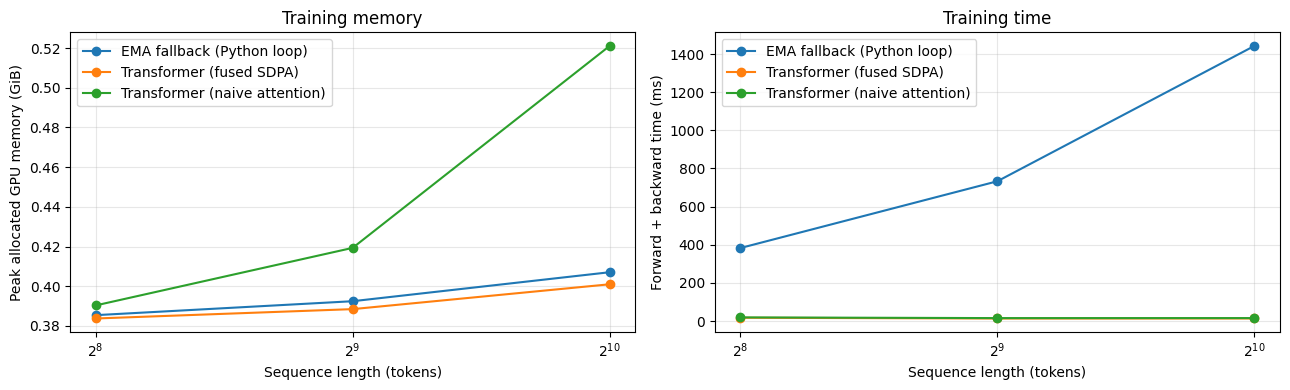

Saved benchmark plot to /scratch/m25mac003/omnidoc_outputs/results/efficiency_benchmark.png
The SSM row measures the EMA Python fallback, not Mamba. Do not use it to claim real Mamba performance.


In [40]:
# Attention and SSM efficiency benchmark.
# Training timing is forward + backward; it does not include an optimizer step.

class NaiveAttnLayer(nn.Module):
    """Softmax(QKᵀ)V attention, which materializes the quadratic attention matrix."""

    def __init__(self, dim=EMBED_DIM, heads=4):
        super().__init__()
        if dim % heads != 0:
            raise ValueError(f"dim={dim} must be divisible by heads={heads}.")

        self.heads = heads
        self.head_dim = dim // heads
        self.norm = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, 3 * dim)
        self.out = nn.Linear(dim, dim)
        self.ff = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, 4 * dim),
            nn.GELU(),
            nn.Linear(4 * dim, dim),
        )

    def _qkv(self, x):
        batch, seq_len, dim = x.shape
        q, k, v = (
            self.qkv(self.norm(x))
            .reshape(batch, seq_len, 3, self.heads, self.head_dim)
            .permute(2, 0, 3, 1, 4)
        )
        return q, k, v

    def forward(self, x):
        batch, seq_len, dim = x.shape
        q, k, v = self._qkv(x)
        attn = (q @ k.transpose(-1, -2) / (self.head_dim ** 0.5)).softmax(dim=-1)
        attended = (attn @ v).transpose(1, 2).reshape(batch, seq_len, dim)
        x = x + self.out(attended)
        return x + self.ff(x)


class SDPALayer(NaiveAttnLayer):
    """Same layer using PyTorch scaled dot-product attention."""

    def forward(self, x):
        batch, seq_len, dim = x.shape
        q, k, v = self._qkv(x)
        attended = F.scaled_dot_product_attention(q, k, v)
        attended = attended.transpose(1, 2).reshape(batch, seq_len, dim)
        x = x + self.out(attended)
        return x + self.ff(x)


def bench(
    make_layer,
    name,
    seq_lens,
    dim=EMBED_DIM,
    layers=4,
    train=False,
    repeats=3,
):
    rows = []

    for seq_len in seq_lens:
        net = nn.Sequential(
            *[make_layer() for _ in range(layers)]
        ).to(device)
        net.train(train)
        x = torch.randn(
            1,
            seq_len,
            dim,
            device=device,
            requires_grad=train,
        )

        try:
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats(device)

            def run_once():
                if train:
                    net.zero_grad(set_to_none=True)

                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    output = net(x)

                if train:
                    output.float().mean().backward()

            context = torch.enable_grad() if train else torch.inference_mode()
            with context:
                run_once()  # warm-up
                torch.cuda.synchronize(device)

                start = torch.cuda.Event(enable_timing=True)
                end = torch.cuda.Event(enable_timing=True)
                start.record()

                for _ in range(repeats):
                    run_once()

                end.record()
                torch.cuda.synchronize(device)

            rows.append({
                "model": name,
                "mode": "train" if train else "infer",
                "seq_len": seq_len,
                "ms": start.elapsed_time(end) / repeats,
                "peak_memory_gib": (
                    torch.cuda.max_memory_allocated(device) / (1024 ** 3)
                ),
            })

        except torch.cuda.OutOfMemoryError:
            rows.append({
                "model": name,
                "mode": "train" if train else "infer",
                "seq_len": seq_len,
                "ms": float("nan"),
                "peak_memory_gib": float("nan"),
            })
            print(f"OOM: {name}, seq_len={seq_len}, train={train}")
        finally:
            del net, x
            torch.cuda.empty_cache()

    return rows


if not torch.cuda.is_available():
    print("Efficiency benchmark requires a CUDA GPU.")
else:
    device = torch.device("cuda")

    # The Python EMA fallback uses sequential Python loops, so keep its
    # benchmark short. Override OMNIDOC_BENCH_FALLBACK=1 for longer runs.
    fallback_bench = not USE_REAL_MAMBA
    if fallback_bench:
        seq_lens = (256, 512, 1024)
        repeats = 1
    else:
        seq_lens = (1024, 2048, 4096, 8192)
        repeats = 3

    bench_rows = []

    for train_mode in (False, True):
        bench_rows += bench(
            NaiveAttnLayer,
            "Transformer (naive attention)",
            seq_lens=seq_lens,
            train=train_mode,
            repeats=repeats,
        )
        bench_rows += bench(
            SDPALayer,
            "Transformer (fused SDPA)",
            seq_lens=seq_lens,
            train=train_mode,
            repeats=repeats,
        )
        bench_rows += bench(
            make_ssm_layer,
            "Mamba selective scan" if USE_REAL_MAMBA else "EMA fallback (Python loop)",
            seq_lens=seq_lens,
            train=train_mode,
            repeats=repeats,
        )

    df_bench = pd.DataFrame(bench_rows)
    csv_path = RESULTS_DIR / "efficiency_benchmark.csv"
    df_bench.to_csv(csv_path, index=False)

    print(df_bench.round(2).to_string(index=False))
    print(f"Saved benchmark data to {csv_path}")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    for name, group in df_bench[df_bench["mode"] == "train"].groupby("model"):
        axes[0].plot(
            group["seq_len"],
            group["peak_memory_gib"],
            "o-",
            label=name,
        )
        axes[1].plot(
            group["seq_len"],
            group["ms"],
            "o-",
            label=name,
        )

    axes[0].set_xlabel("Sequence length (tokens)")
    axes[0].set_ylabel("Peak allocated GPU memory (GiB)")
    axes[0].set_title("Training memory")
    axes[1].set_xlabel("Sequence length (tokens)")
    axes[1].set_ylabel("Forward + backward time (ms)")
    axes[1].set_title("Training time")

    for axis in axes:
        axis.set_xscale("log", base=2)
        axis.grid(alpha=0.3)
        axis.legend()

    plt.tight_layout()
    plot_path = RESULTS_DIR / "efficiency_benchmark.png"
    plt.savefig(plot_path, dpi=150)
    plt.show()
    print(f"Saved benchmark plot to {plot_path}")

    if fallback_bench:
        print(
            "The SSM row measures the EMA Python fallback, not Mamba. "
            "Do not use it to claim real Mamba performance."
        )

Training curves saved to: /scratch/m25mac003/omnidoc_outputs/results/training_curves.png


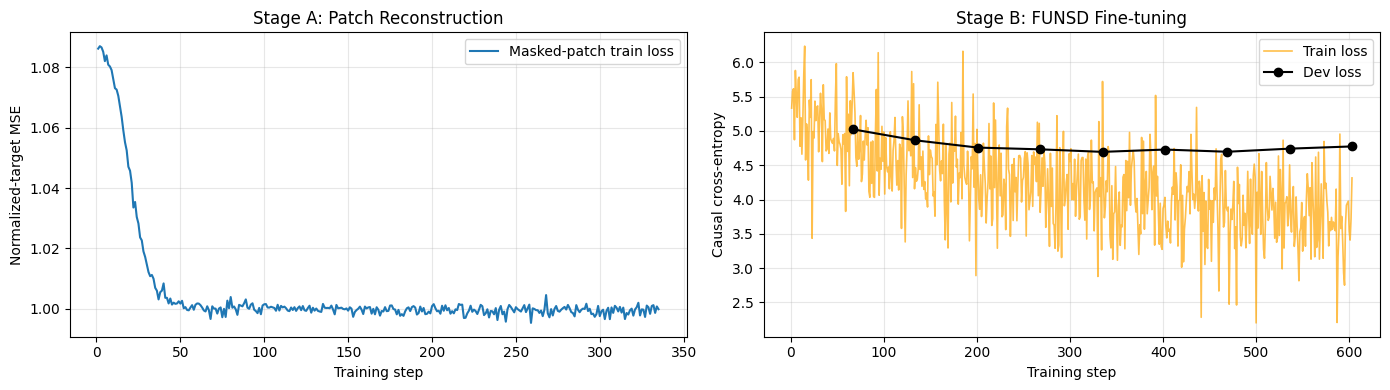

In [41]:
# Visualize Stage A and Stage B training curves.

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

if pretrain_losses:
    axes[0].plot(
        np.arange(1, len(pretrain_losses) + 1),
        pretrain_losses,
        linewidth=1.5,
        label="Masked-patch train loss",
    )
axes[0].set_xlabel("Training step")
axes[0].set_ylabel("Normalized-target MSE")
axes[0].set_title("Stage A: Patch Reconstruction")
axes[0].grid(True, alpha=0.3)
if pretrain_losses:
    axes[0].legend()

if finetune_losses:
    train_steps = np.arange(1, len(finetune_losses) + 1)
    axes[1].plot(
        train_steps,
        finetune_losses,
        linewidth=1.2,
        color="orange",
        alpha=0.7,
        label="Train loss",
    )

if validation_losses:
    # Stage B completes full epochs, even when early stopping is used.
    validation_steps = (
        np.arange(1, len(validation_losses) + 1) * len(train_loader)
    )
    axes[1].plot(
        validation_steps,
        validation_losses,
        "o-",
        color="black",
        label="Dev loss",
    )

axes[1].set_xlabel("Training step")
axes[1].set_ylabel("Causal cross-entropy")
axes[1].set_title("Stage B: FUNSD Fine-tuning")
axes[1].grid(True, alpha=0.3)
if finetune_losses or validation_losses:
    axes[1].legend()

plt.tight_layout()
curve_path = RESULTS_DIR / "training_curves.png"
plt.savefig(curve_path, dpi=150, bbox_inches="tight")
print("Training curves saved to:", curve_path)
plt.show()

## Visual diagnostics: learned features and patch reconstruction

The next figure connects training to model behavior. It compares an original patch grid with the reconstruction head output, projects each validation document's visual representation into 2D with PCA, and summarizes token confidence on the held-out set.

Saved model diagnostics to /scratch/m25mac003/omnidoc_outputs/results/model_visual_diagnostics.png
Visual feature tensor: (8, 2205, 128)
Mean target-token max probability: 0.3173


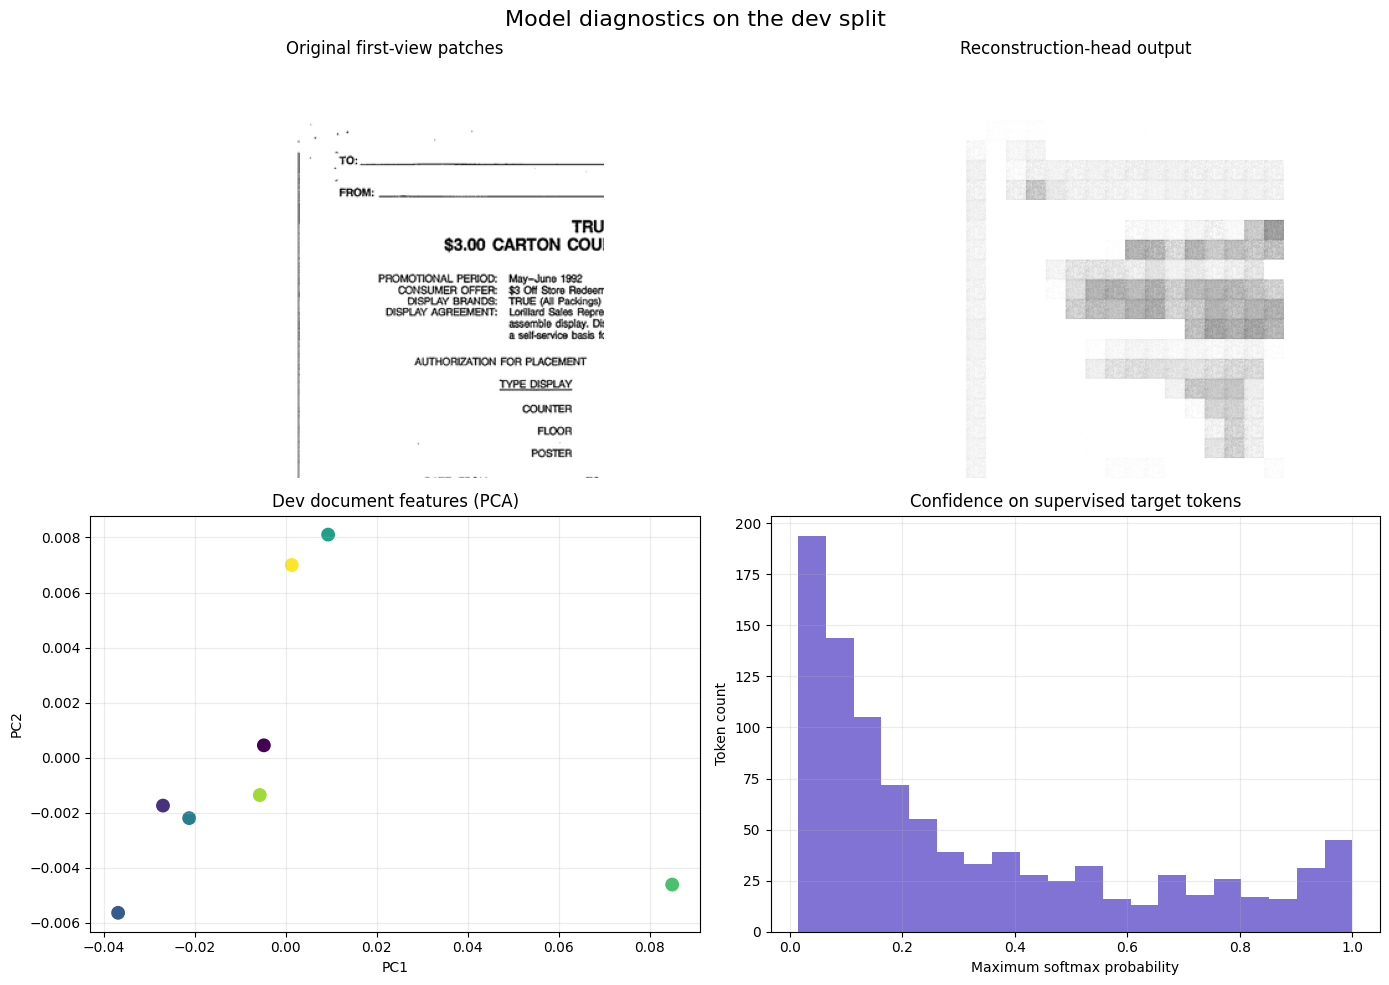

OmniDocMambaV2(
  (patch_projector): PatchProjector(
    (proj): Conv2d(3, 128, kernel_size=(16, 16), stride=(16, 16))
  )
  (spatial_embedding): SpatialEmbedding(
    (row_embedding): Embedding(100, 128)
    (col_embedding): Embedding(100, 128)
  )
  (graph_attention): LocalGraphAttention(
    (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
    )
    (output): Sequential(
      (0): Linear(in_features=128, out_features=256, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=256, out_features=128, bias=True)
    )
  )
  (mamba_core): BidirectionalMambaCore(
    (layers): ModuleList(
      (0-3): 4 x EMAGatedBlock(
        (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (in_proj): Linear(in_features=128, out_features=512, bias=True)
        (state_proj): Linear(in_features=256, out_features=256,

In [43]:
# Visualize dev-set features, masked-patch reconstruction, and target-token confidence.
from sklearn.decomposition import PCA

if len(dev_dataset) < 2:
    raise ValueError("PCA visualization needs at least two dev documents.")

was_training = model.training
model.eval()

visual_batch = next(iter(DataLoader(
    dev_dataset,
    batch_size=min(8, len(dev_dataset)),
    shuffle=False,
    num_workers=0,
)))

visual_images = visual_batch["images"].to(device, non_blocking=True)
input_ids = visual_batch["input_ids"].to(device, non_blocking=True)
attention_mask = visual_batch["attention_mask"].to(device, non_blocking=True)
labels = visual_batch["labels"].to(device, non_blocking=True)

batch_size, num_views, channels, image_height, image_width = visual_images.shape
patch_height = image_height // PATCH_SIZE
patch_width = image_width // PATCH_SIZE
tokens_per_view = patch_height * patch_width
total_visual_tokens = num_views * tokens_per_view

# The visual encoder takes patch_mask as a keyword argument.
# Use an unmasked pass for document features.
with torch.inference_mode():
    if device.type == "cuda":
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            visual_features = model.forward_visual(visual_images)
            visual_logits = model(
                visual_images,
                visual_batch["row_indices"].to(device, non_blocking=True),
                visual_batch["col_indices"].to(device, non_blocking=True),
                input_ids,
                attention_mask,
            )

            # Stage A trained reconstruction on masked patches, so evaluate
            # the reconstruction head with masked visual inputs.
            patch_mask = torch.rand(
                batch_size,
                total_visual_tokens,
                device=device,
            ) < 0.5
            masked_features = model.forward_visual(
                visual_images,
                patch_mask=patch_mask,
            )
            reconstruction = model.reconstruction_head(masked_features)
    else:
        visual_features = model.forward_visual(visual_images)
        visual_logits = model(
            visual_images,
            visual_batch["row_indices"].to(device),
            visual_batch["col_indices"].to(device),
            input_ids,
            attention_mask,
        )
        patch_mask = torch.rand(batch_size, total_visual_tokens, device=device) < 0.5
        masked_features = model.forward_visual(
            visual_images,
            patch_mask=patch_mask,
        )
        reconstruction = model.reconstruction_head(masked_features)

# Convert the first view's predicted normalized patches back to pixel range.
original = visual_images[0, 0].detach().float().cpu()
original_patches = F.unfold(
    original.unsqueeze(0),
    kernel_size=PATCH_SIZE,
    stride=PATCH_SIZE,
).transpose(1, 2)[0]

first_view_predictions = reconstruction[
    0, :tokens_per_view
].detach().float().cpu()

patch_mean = original_patches.mean(dim=-1, keepdim=True)
patch_std = original_patches.std(
    dim=-1,
    keepdim=True,
    unbiased=False,
).clamp_min(1e-6)

# The reconstruction head was trained to predict standardized patches.
reconstructed_patches = first_view_predictions * patch_std + patch_mean

original_grid = (
    original_patches.reshape(-1, channels, PATCH_SIZE, PATCH_SIZE)
    .mean(dim=1)
    .numpy()
)
reconstructed_grid = (
    reconstructed_patches.reshape(-1, channels, PATCH_SIZE, PATCH_SIZE)
    .mean(dim=1)
    .clamp(0, 1)
    .numpy()
)

original_grid = (
    original_grid
    .reshape(patch_height, patch_width, PATCH_SIZE, PATCH_SIZE)
    .transpose(0, 2, 1, 3)
    .reshape(image_height, image_width)
)
reconstructed_grid = (
    reconstructed_grid
    .reshape(patch_height, patch_width, PATCH_SIZE, PATCH_SIZE)
    .transpose(0, 2, 1, 3)
    .reshape(image_height, image_width)
)

# PCA: one feature vector per dev document.
document_embeddings = visual_features.mean(dim=1).detach().float().cpu().numpy()
pca_coordinates = PCA(n_components=2, random_state=42).fit_transform(
    document_embeddings
)

# Confidence only on supervised next-token targets; this is diagnostic,
# not a calibrated probability.
shifted_logits = visual_logits[:, :-1, :].float()
shifted_labels = labels[:, 1:]
valid_targets = shifted_labels.ne(-100)
confidence = (
    shifted_logits.softmax(dim=-1).max(dim=-1).values[valid_targets]
    .detach()
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].imshow(original_grid, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Original first-view patches")
axes[0, 0].axis("off")

axes[0, 1].imshow(reconstructed_grid, cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title("Reconstruction-head output")
axes[0, 1].axis("off")

axes[1, 0].scatter(
    pca_coordinates[:, 0],
    pca_coordinates[:, 1],
    c=np.arange(len(pca_coordinates)),
    cmap="viridis",
    s=80,
)
axes[1, 0].set_title("Dev document features (PCA)")
axes[1, 0].set_xlabel("PC1")
axes[1, 0].set_ylabel("PC2")
axes[1, 0].grid(True, alpha=0.25)

if len(confidence):
    axes[1, 1].hist(confidence, bins=20, color="slateblue", alpha=0.85)
    axes[1, 1].set_title("Confidence on supervised target tokens")
    axes[1, 1].set_xlabel("Maximum softmax probability")
    axes[1, 1].set_ylabel("Token count")
    axes[1, 1].grid(True, alpha=0.25)
else:
    axes[1, 1].text(0.5, 0.5, "No supervised target tokens", ha="center")
    axes[1, 1].axis("off")

fig.suptitle("Model diagnostics on the dev split", fontsize=16)
plt.tight_layout()

diagnostics_path = RESULTS_DIR / "model_visual_diagnostics.png"
plt.savefig(diagnostics_path, dpi=160, bbox_inches="tight")
print(f"Saved model diagnostics to {diagnostics_path}")
print(f"Visual feature tensor: {tuple(visual_features.shape)}")
if len(confidence):
    print(f"Mean target-token max probability: {confidence.mean():.4f}")

plt.show()
model.train(was_training)

In [44]:
# Save the best-dev model checkpoint and final test metrics.

checkpoint = {
    "model_state_dict": model.state_dict(),
    "best_dev_epoch": best_epoch,
    "best_dev_loss": best_dev,
    "eval_metrics": eval_metrics,
    "config": {
        "embed_dim": EMBED_DIM,
        "patch_size": PATCH_SIZE,
        "crop_size": CROP_SIZE,
        "grid_size": GRID_SIZE,
        "num_views": GRID_SIZE * GRID_SIZE + 1,
        "num_ssm_layers": len(model.mamba_core.layers),
        "ssm_type": (
            "mamba_ssm"
            if USE_REAL_MAMBA
            else "gated-EMA fallback (not Mamba)"
        ),
        "llm_model": LLM_MODEL_NAME,
        "train_documents": len(train_documents),
        "dev_documents": len(dev_documents),
        "test_documents": len(validation_documents),
        "batch_size": BATCH_SIZE,
        "dataset": DATASET_NAME,
        "max_seq_len": 128,
    },
}

checkpoint_path = MODELS_DIR / "omnidoc_mamba_v3_checkpoint.pt"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
torch.save(checkpoint, checkpoint_path)

print(f"Best-dev model checkpoint saved to: {checkpoint_path}")
print(f"Best dev epoch: {best_epoch} | Best dev loss: {best_dev:.4f}")

Best-dev model checkpoint saved to: /scratch/m25mac003/omnidoc_outputs/models/omnidoc_mamba_v3_checkpoint.pt
Best dev epoch: 5 | Best dev loss: 4.6946


## Step 6: Inference & Production Testing

In [45]:
# OCR-free inference for images and multi-page PDFs.

@torch.inference_mode()
def infer_document(
    model,
    document,
    tokenizer,
    device,
    prompt=PROMPT_TEXT,
    max_new_tokens=128,
    max_pages=12,
):
    if max_pages < 1:
        raise ValueError("max_pages must be at least 1.")

    pages = load_document_pages(document, max_pages=max_pages)
    if not pages:
        raise ValueError(
            "The document did not contain a readable image or PDF page."
        )

    was_training = model.training
    model.eval()
    page_results = []

    try:
        for page_number, page in enumerate(pages, start=1):
            crops = dynamic_crop_images(page)
            crop_tensors = [
                torch.from_numpy(crop.astype(np.float32) / 255.0)
                .permute(2, 0, 1)
                for crop in crops
            ]
            images = torch.stack(crop_tensors).unsqueeze(0).to(
                device,
                non_blocking=True,
            )

            if device.type == "cuda":
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    page_text = model.generate_text(
                        images,
                        prompt,
                        tokenizer,
                        device,
                        max_new_tokens=max_new_tokens,
                    )
            else:
                page_text = model.generate_text(
                    images,
                    prompt,
                    tokenizer,
                    device,
                    max_new_tokens=max_new_tokens,
                )

            page_text = str(page_text or "").strip()
            if not page_text:
                page_text = (
                    "[No text generated for this page. "
                    "The checkpoint may need supervised training.]"
                )

            page_results.append({
                "page": page_number,
                "text": page_text,
                "views": len(crops),
                "image_size": page.size,
            })
    finally:
        model.train(was_training)

    return {
        "extracted_text": "\n\n".join(
            f"--- Page {item['page']} ---\n{item['text']}"
            for item in page_results
        ),
        "pages": page_results,
        "page_count": len(page_results),
        "views": sum(item["views"] for item in page_results),
        "image_size": page_results[0]["image_size"],
    }


print("OCR-free image and multi-page PDF inference function defined.")

OCR-free image and multi-page PDF inference function defined.


In [46]:
# Qualitative inference example from the held-out FUNSD test split.

if not validation_documents:
    raise ValueError("The FUNSD test split is empty.")

test_image = validation_documents[0]["image"]

print("Running OCR-free inference on one held-out test document...")
result = infer_document(
    model,
    test_image,
    tokenizer,
    device,
    prompt=PROMPT_TEXT,
    max_new_tokens=128,
)

print("\nInference results:")
print(f"  Pages: {result['page_count']}")
print(f"  Visual views: {result['views']}")
print(f"  Input size: {result['image_size']}")
print(f"  Extracted text: {result['extracted_text'][:500]}")
print("\nInference complete.")

Running OCR-free inference on one held-out test document...

Inference results:
  Pages: 1
  Visual views: 5
  Input size: (754, 1000)
  Extracted text: --- Page 1 ---
DATE: TO: FROM: B&W COMPANY NAME: PROJECT NUMBER: REQUESTED BY: J. R. WILSON, M. LORILLARDON, T. HARRISBURG, C. P. O'MEE (S) - NEW YORK TIMES NO. 1- THE LAST DAY IN A LONG TIME AND HAVE NEVER BEEN SUGGLY AGAINST ANY OF THESE PRODUCTIONS OR

Inference complete.


## Five random held-out documents: complete model walkthrough

This section samples five documents from the FUNSD test split with a fixed seed for reproducibility. For every document it displays the original page, all five visual views, the topological mesh, the visual feature tensor, model confidence, predicted text, and ground-truth text. The resulting figure and table are saved for presentation.

Sample seed: 2026
Sampled test indices: [7, 20, 32, 41, 6]
Saved figure: /scratch/m25mac003/omnidoc_outputs/results/five_test_documents_process.png
Saved table: /scratch/m25mac003/omnidoc_outputs/results/five_test_documents_process.csv


,document_index,target_text,predicted_text
0,7,TO: FROM: SUBJECT: GEOGRAPHY REGION: FULL X DI...,DATE: TO: FROM: B&W COMPANY NAME: PROJECT NUMB...
1,20,31 1818 22 15 24 19 15 209 32 151/15 81/9 138/...,DATE: TO: FROM: B&W COMPANY NAME: PROJECT NUMB...
2,32,TO: FROM: Mrs. K. A. Sparrow R. G. Ryan JUNE7 ...,DATE: TO: FROM: B&W COMPANY NAME: PROJECT NUMB...
3,41,Name: First Title Middle Last Institution: Str...,DATE: TO: FROM: B&W COMPANY NAME: PROJECT NUMB...
4,6,TO: FROM: SUBJECT: X PRE- SELL DISTRIBUTION Sh...,DATE: TO: FROM: B&W COMPANY NAME: PROJECT NUMB...


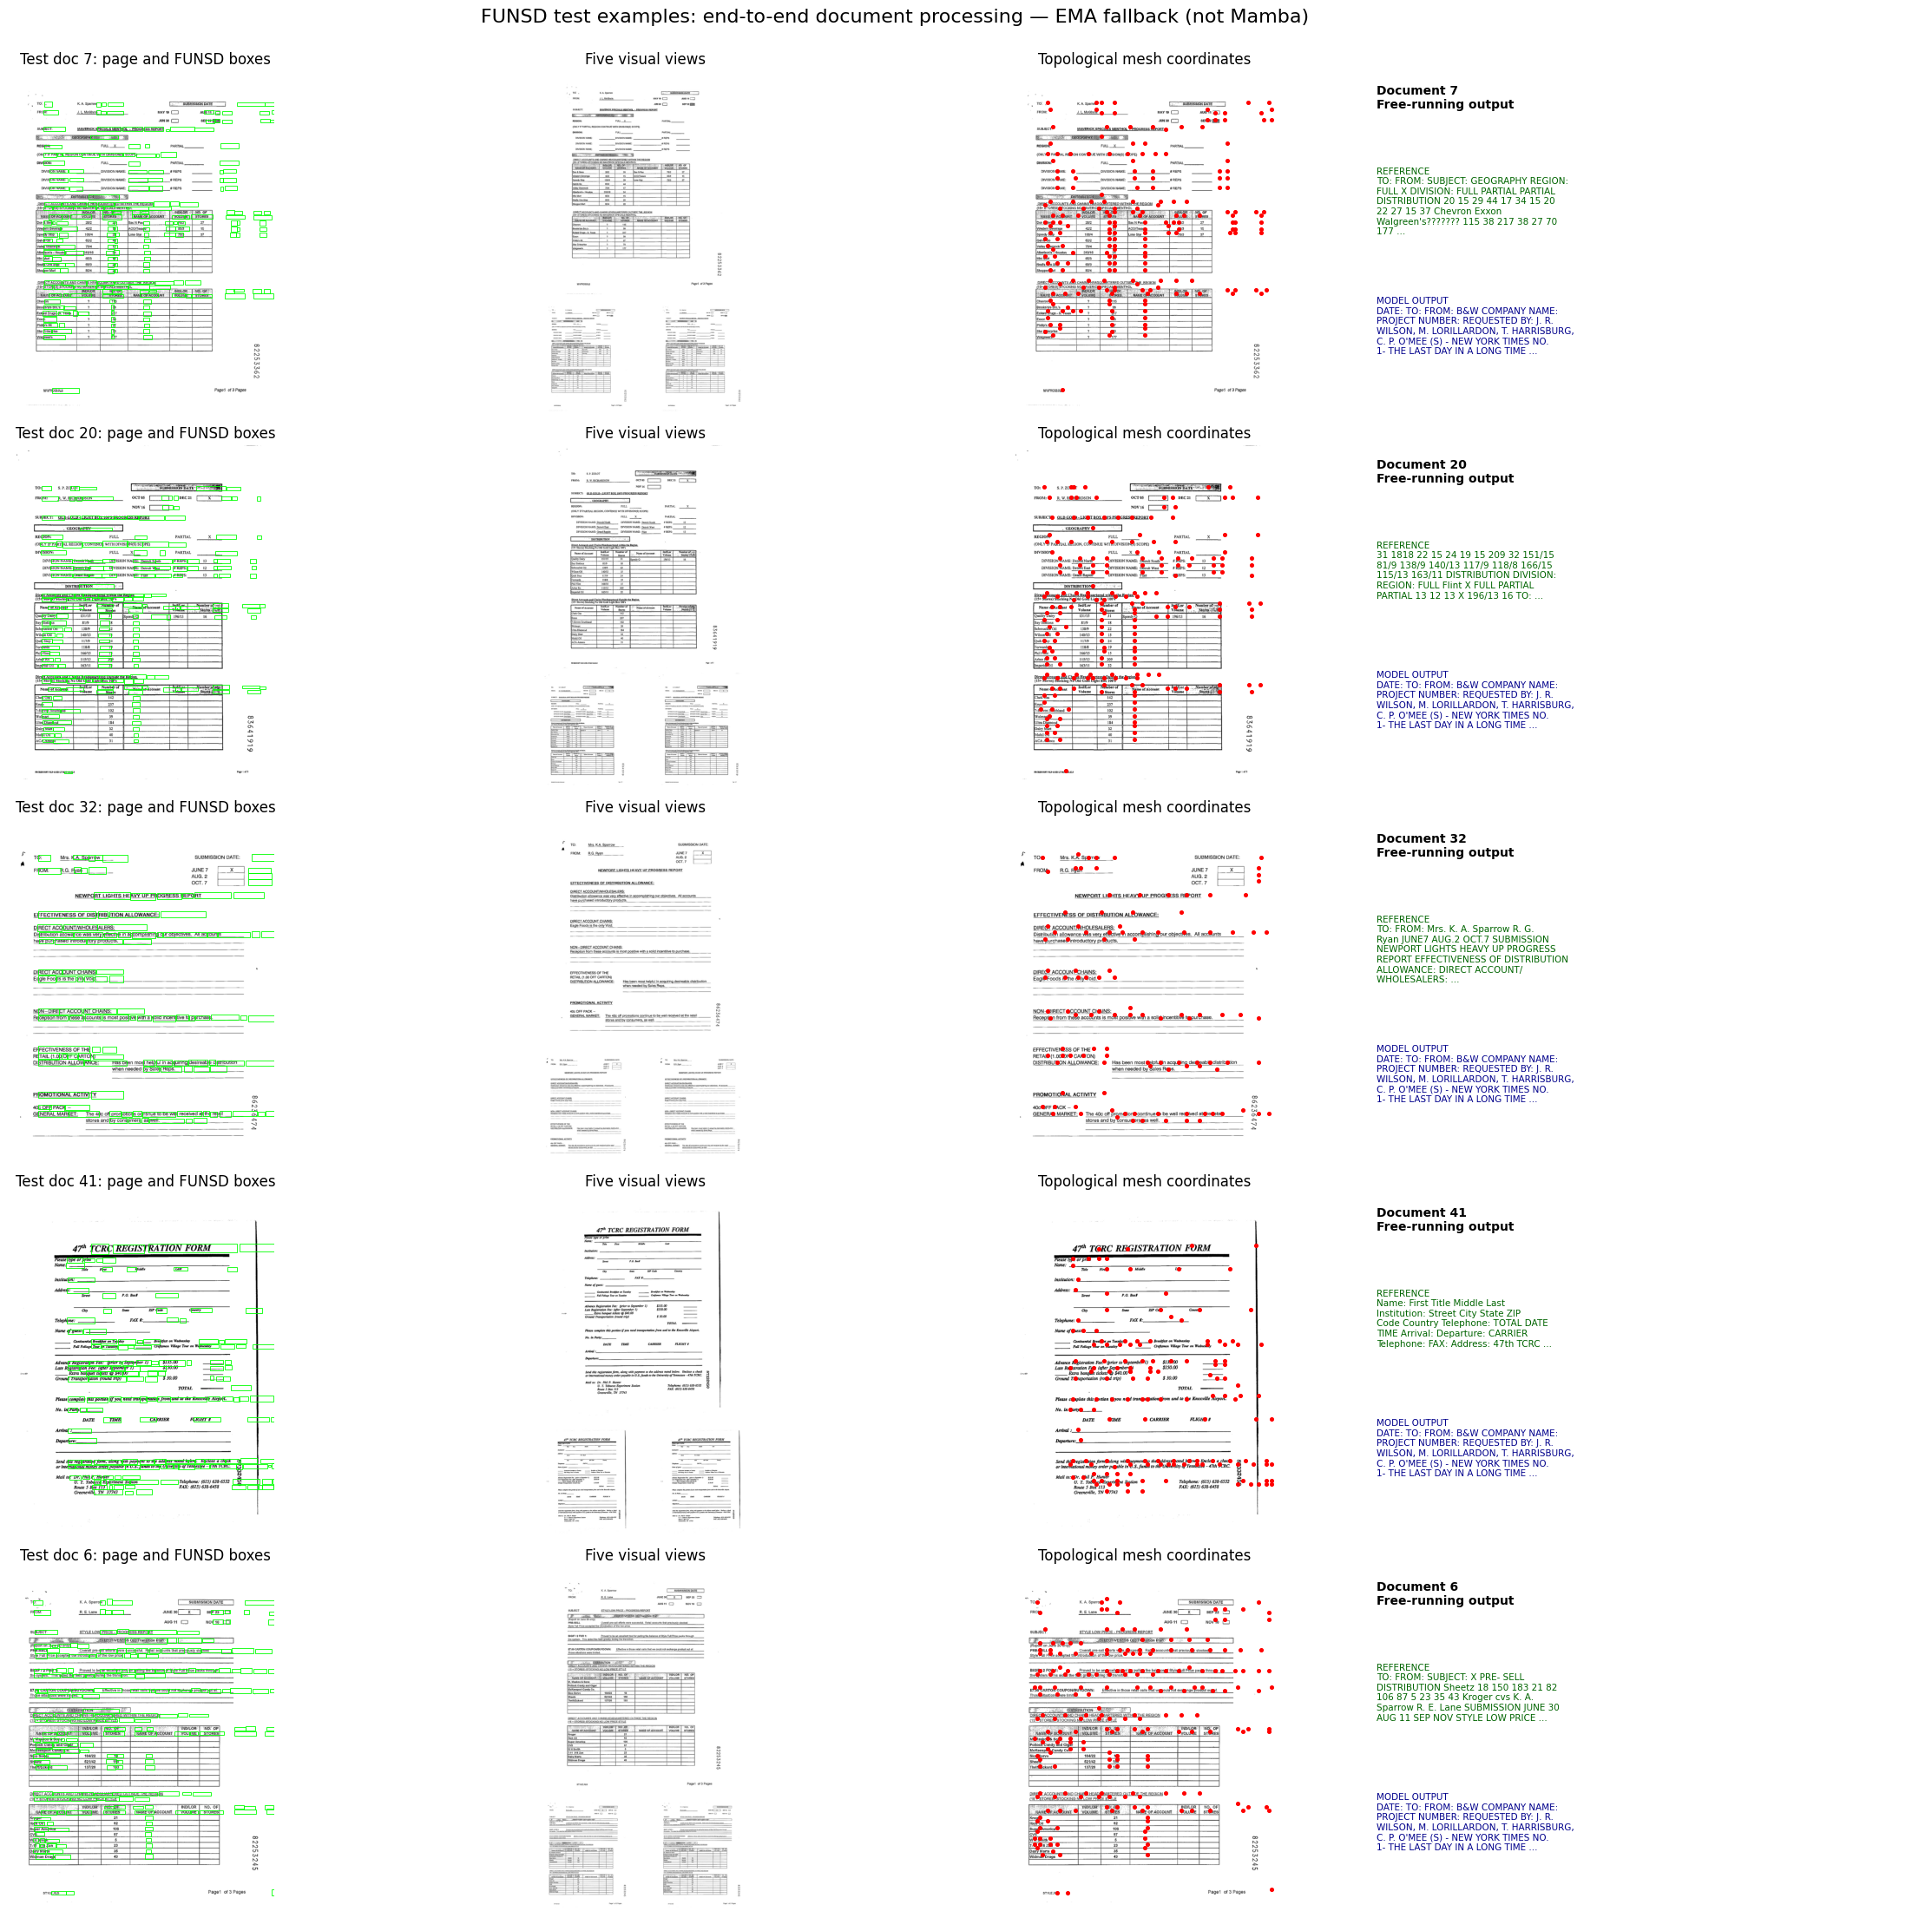

In [47]:
# Visualize five random held-out FUNSD documents.
# This is qualitative final-test reporting only; do not use it for model selection.

import textwrap
from matplotlib.patches import Rectangle
from IPython.display import display

if not validation_documents:
    raise ValueError("The FUNSD test split is empty.")

SAMPLE_SEED = 2026
SAMPLE_COUNT = min(5, len(validation_documents))
sample_rng = random.Random(SAMPLE_SEED)
sample_indices = sample_rng.sample(
    range(len(validation_documents)),
    SAMPLE_COUNT,
)

was_training = model.training
model.eval()
process_rows = []

figure, axes = plt.subplots(
    SAMPLE_COUNT,
    4,
    figsize=(24, 4.5 * SAMPLE_COUNT),
    squeeze=False,
)


def preview_text(text, max_chars=180):
    text = " ".join(str(text).split())
    if len(text) <= max_chars:
        return text
    return text[:max_chars].rsplit(" ", 1)[0] + " ..."


try:
    for display_index, document_index in enumerate(sample_indices):
        record = validation_documents[document_index]
        page = record["image"].convert("RGB")
        page_width, page_height = page.size
        crops = dynamic_crop_images(page)
        mesh_boxes = create_topological_mesh(record["boxes"], page.size)

        # Decode the actual truncated target used by the dataset/evaluation.
        dataset_item = validation_dataset[document_index]
        target_ids = dataset_item["labels"]
        target_ids = target_ids[target_ids != -100].tolist()
        target_text = tokenizer.decode(
            target_ids,
            skip_special_tokens=True,
        ).strip()

        image_batch = dataset_item["images"].unsqueeze(0).to(
            device,
            non_blocking=True,
        )

        if device.type == "cuda":
            with torch.inference_mode(), torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
            ):
                prediction_text = model.generate_text(
                    image_batch,
                    PROMPT_TEXT,
                    tokenizer,
                    device,
                    max_new_tokens=128,
                )
        else:
            with torch.inference_mode():
                prediction_text = model.generate_text(
                    image_batch,
                    PROMPT_TEXT,
                    tokenizer,
                    device,
                    max_new_tokens=128,
                )

        prediction_text = str(prediction_text or "").strip()
        process_rows.append({
            "document_index": document_index,
            "target_text": target_text,
            "predicted_text": prediction_text,
        })

        # Page with FUNSD word boxes.
        page_axis = axes[display_index, 0]
        page_axis.imshow(page)
        for box in record["boxes"]:
            x_min, x_max = min(box["x"]), max(box["x"])
            y_min, y_max = min(box["y"]), max(box["y"])
            page_axis.add_patch(Rectangle(
                (x_min, y_min),
                x_max - x_min,
                y_max - y_min,
                fill=False,
                edgecolor="lime",
                linewidth=0.6,
            ))
        page_axis.set_title(f"Test doc {document_index}: page and FUNSD boxes")
        page_axis.axis("off")

        # Four local crops plus the global view.
        crop_montage = np.concatenate(
            [
                np.concatenate(crops[:2], axis=1),
                np.concatenate(crops[2:4], axis=1),
                np.concatenate([crops[4], crops[4]], axis=1),
            ],
            axis=0,
        )
        axes[display_index, 1].imshow(crop_montage)
        axes[display_index, 1].set_title("Five visual views")
        axes[display_index, 1].axis("off")

        # Topological mesh points.
        mesh_axis = axes[display_index, 2]
        mesh_axis.imshow(page)
        for mesh_box in mesh_boxes:
            mesh_x = mesh_box["col_idx"] / 100 * page_width
            mesh_y = mesh_box["row_idx"] / 100 * page_height
            mesh_axis.scatter(mesh_x, mesh_y, s=7, c="red")
        mesh_axis.set_title("Topological mesh coordinates")
        mesh_axis.axis("off")

        # Reference and free-running model output.
        text_axis = axes[display_index, 3]
        text_axis.set_facecolor("#f5f7fa")
        text_axis.axis("off")
        text_axis.text(
            0.02, 0.96,
            f"Document {document_index}\nFree-running output",
            va="top",
            fontsize=10,
            weight="bold",
        )
        text_axis.text(
            0.02, 0.72,
            "REFERENCE\n" + textwrap.fill(preview_text(target_text), width=38),
            va="top",
            fontsize=7.5,
            color="darkgreen",
        )
        text_axis.text(
            0.02, 0.34,
            "MODEL OUTPUT\n" + textwrap.fill(preview_text(prediction_text), width=38),
            va="top",
            fontsize=7.5,
            color="darkblue",
        )

    model_name = (
        "Mamba selective scan"
        if USE_REAL_MAMBA
        else "EMA fallback (not Mamba)"
    )
    figure.suptitle(
        f"FUNSD test examples: end-to-end document processing — {model_name}",
        fontsize=16,
    )
    plt.tight_layout(rect=(0, 0, 1, 0.98))

    process_figure_path = RESULTS_DIR / "five_test_documents_process.png"
    figure.savefig(process_figure_path, dpi=150, bbox_inches="tight")

    process_table = pd.DataFrame(process_rows)
    process_table_path = RESULTS_DIR / "five_test_documents_process.csv"
    process_table.to_csv(process_table_path, index=False)

    print(f"Sample seed: {SAMPLE_SEED}")
    print(f"Sampled test indices: {sample_indices}")
    print(f"Saved figure: {process_figure_path}")
    print(f"Saved table: {process_table_path}")
    display(process_table)

    plt.show()
finally:
    model.train(was_training)

### Individual document views

The same five documents are also rendered separately, one figure per document, so each result can be shown clearly in a presentation or inspected independently.

Saved /scratch/m25mac003/omnidoc_outputs/results/test_document_1_index_7.png


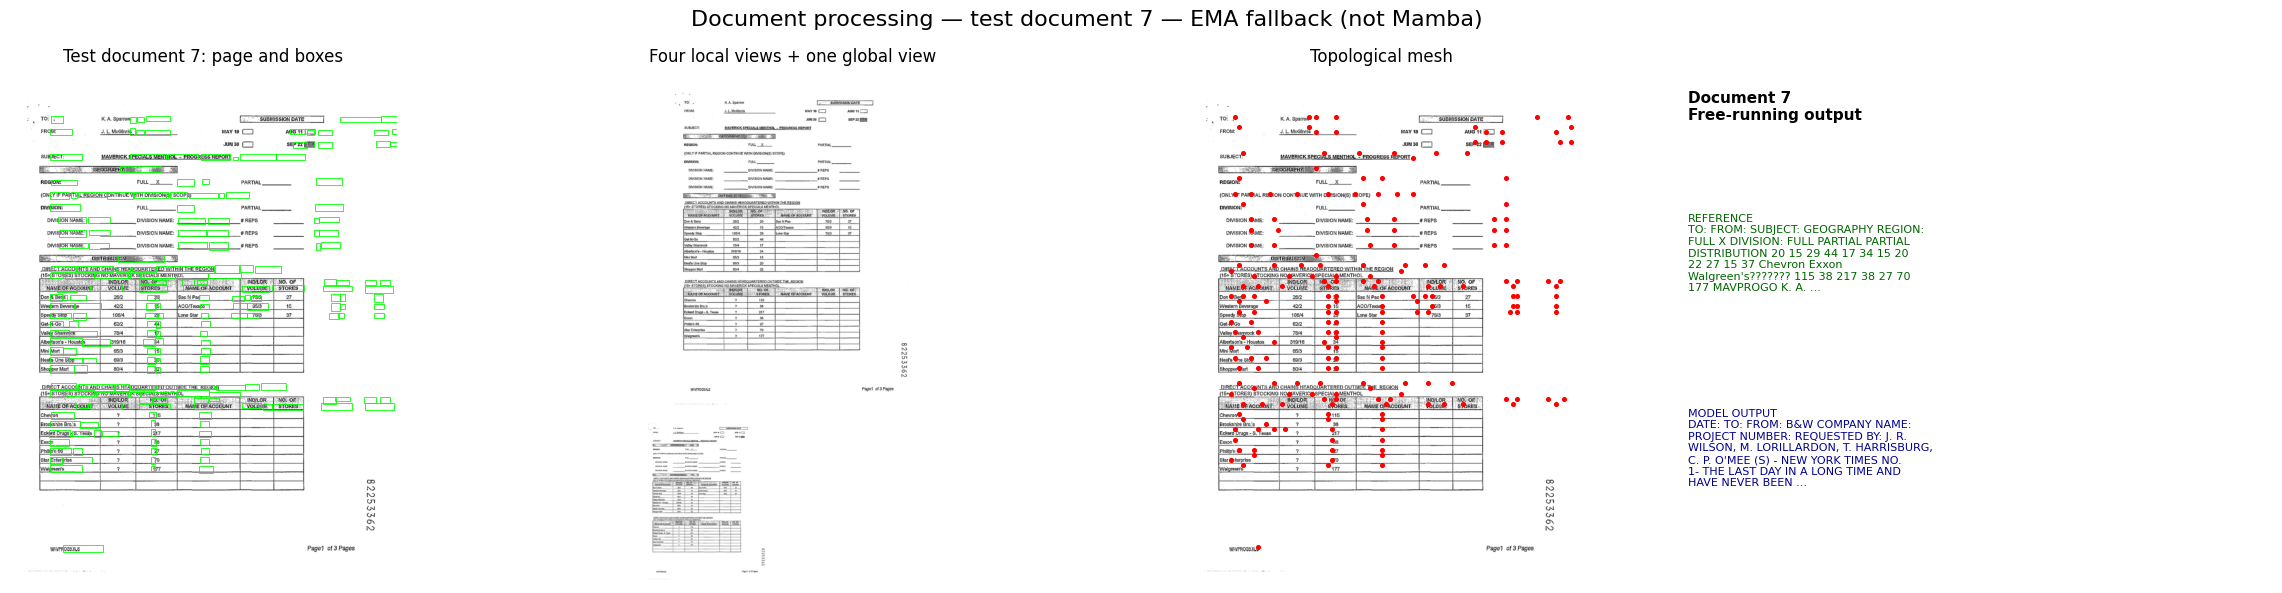

Saved /scratch/m25mac003/omnidoc_outputs/results/test_document_2_index_20.png


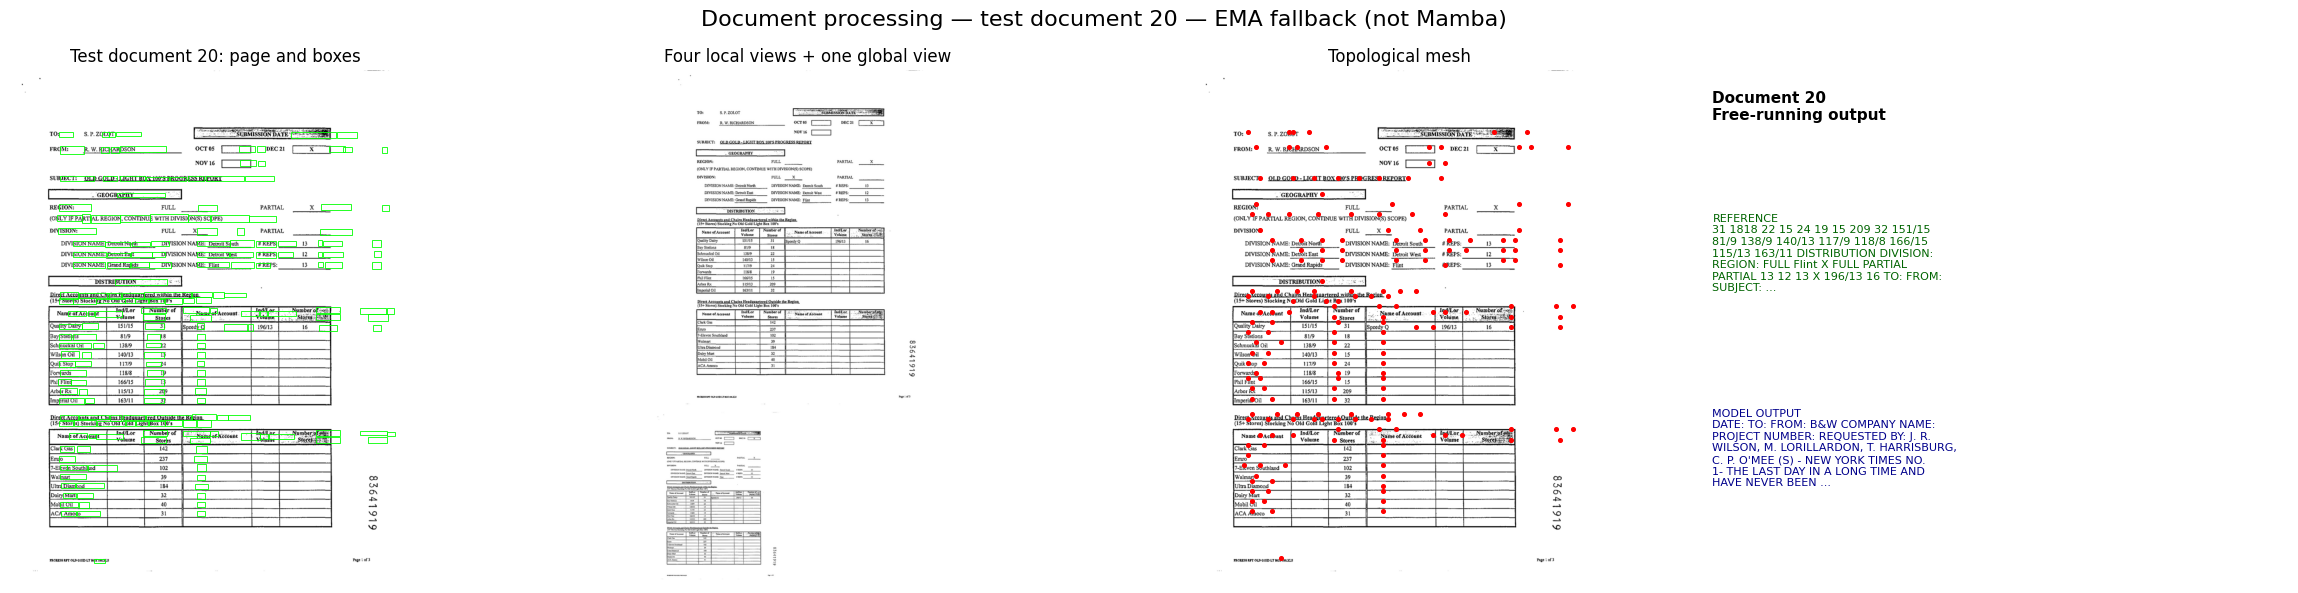

Saved /scratch/m25mac003/omnidoc_outputs/results/test_document_3_index_32.png


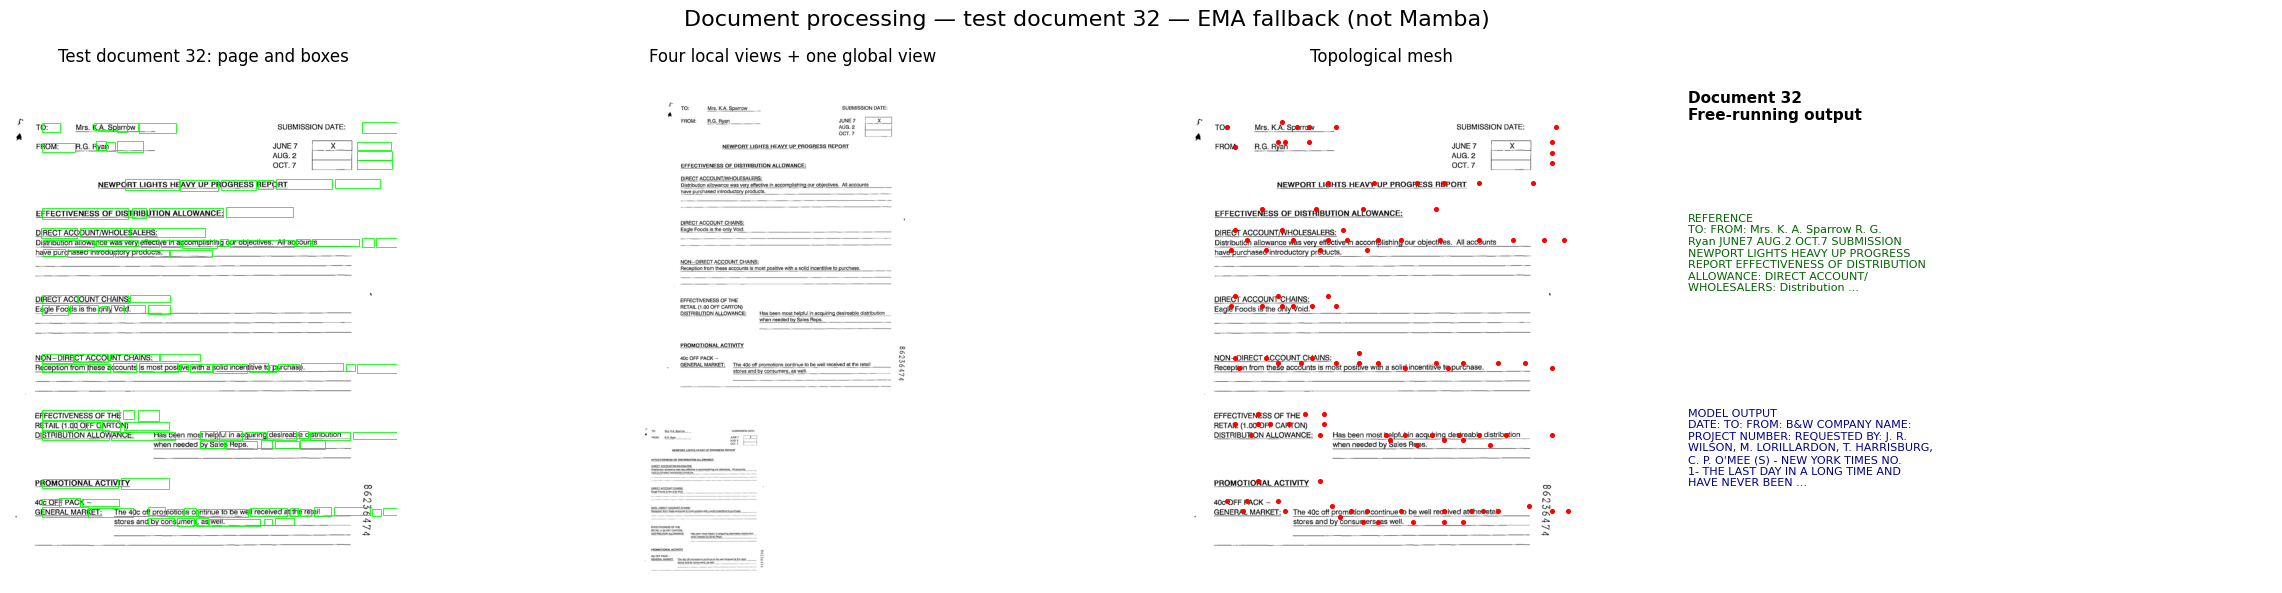

Saved /scratch/m25mac003/omnidoc_outputs/results/test_document_4_index_41.png


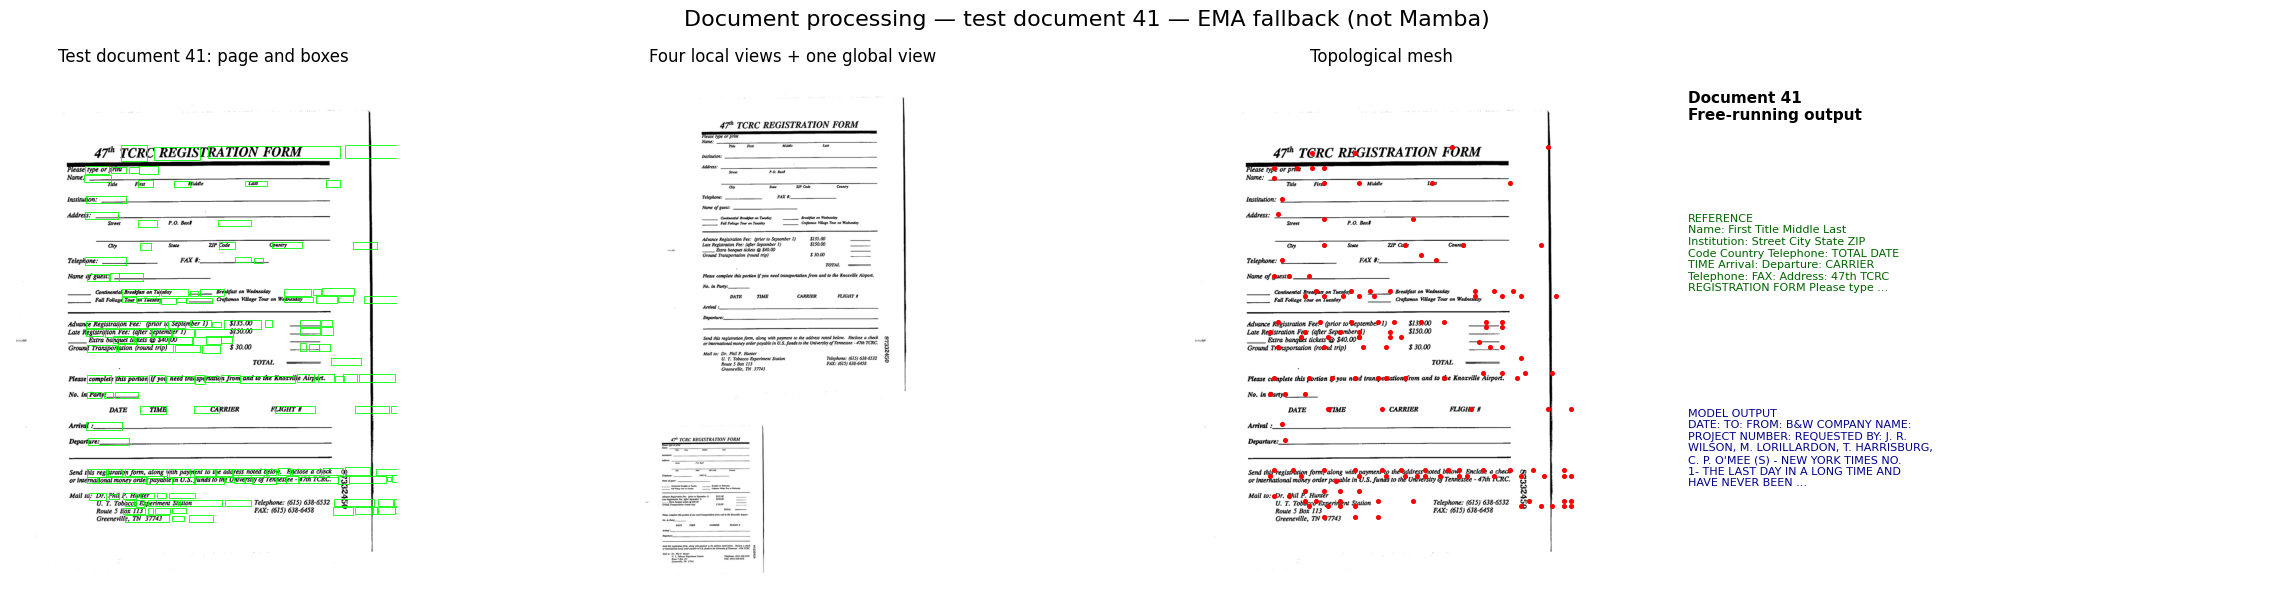

Saved /scratch/m25mac003/omnidoc_outputs/results/test_document_5_index_6.png


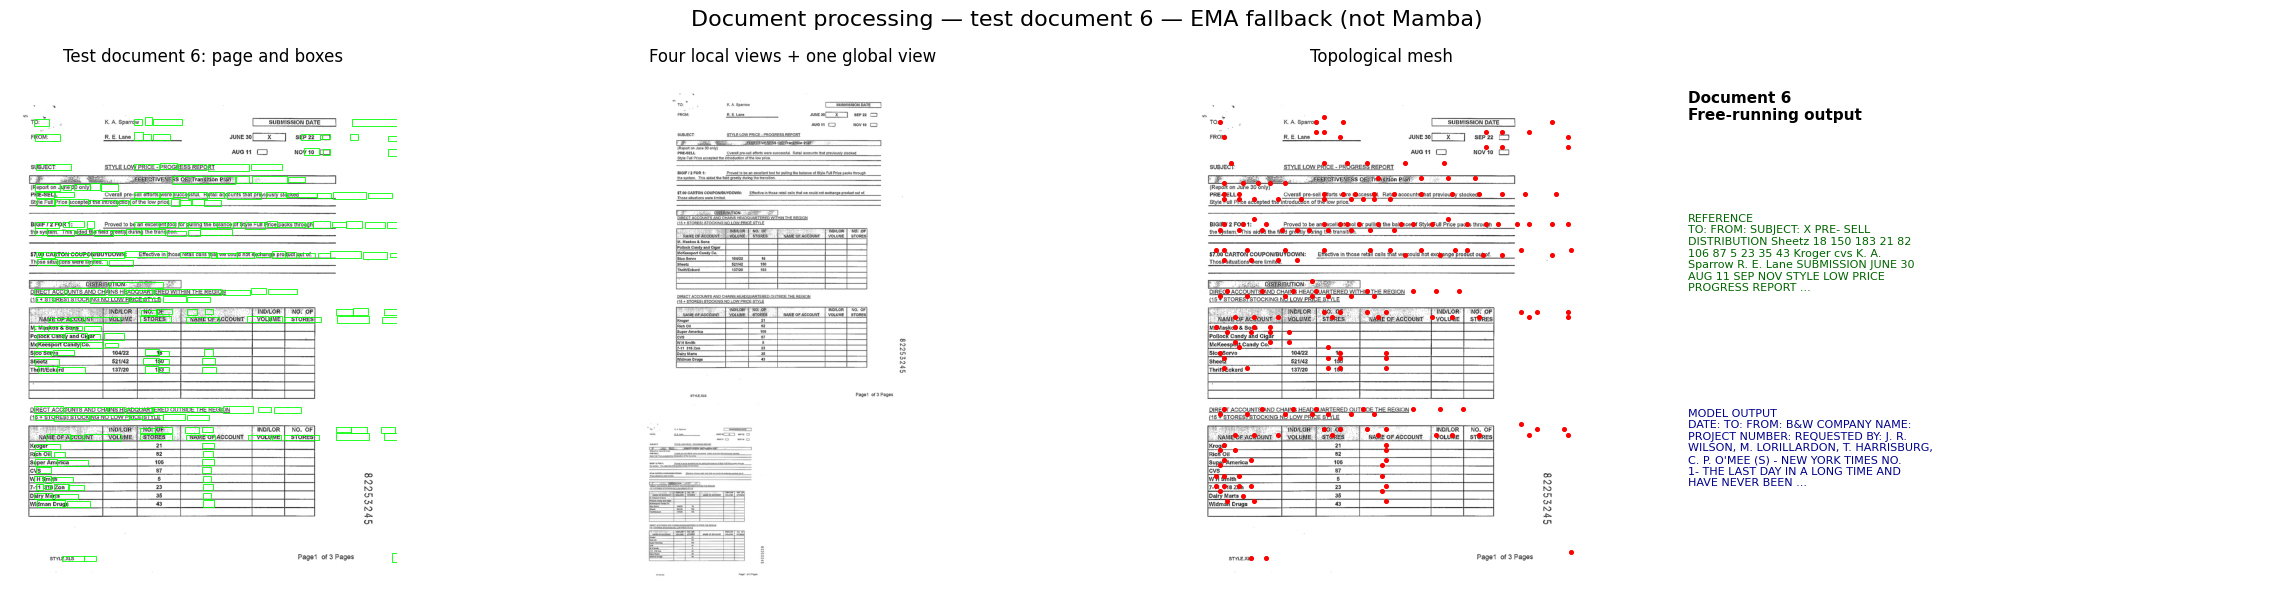

Generated 5 separate document figures.


In [48]:
# Save and display one figure per sampled FUNSD test document.

from IPython.display import display

if not validation_documents:
    raise ValueError("The FUNSD test split is empty.")

if "sample_indices" not in globals():
    sample_rng = random.Random(2026)
    sample_indices = sample_rng.sample(
        range(len(validation_documents)),
        min(5, len(validation_documents)),
    )

individual_output_paths = []
was_training = model.training
model.eval()

try:
    for display_index, document_index in enumerate(sample_indices, start=1):
        record = validation_documents[document_index]
        page = record["image"].convert("RGB")
        page_width, page_height = page.size
        crops = dynamic_crop_images(page)
        mesh_boxes = create_topological_mesh(record["boxes"], page.size)
        dataset_item = validation_dataset[document_index]

        # Match the reference text used by the evaluation dataset.
        target_ids = dataset_item["labels"]
        target_ids = target_ids[target_ids != -100].tolist()
        target_text = tokenizer.decode(
            target_ids,
            skip_special_tokens=True,
        ).strip()

        image_batch = dataset_item["images"].unsqueeze(0).to(
            device,
            non_blocking=True,
        )

        if device.type == "cuda":
            with torch.inference_mode(), torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
            ):
                prediction_text = model.generate_text(
                    image_batch,
                    PROMPT_TEXT,
                    tokenizer,
                    device,
                    max_new_tokens=128,
                )
        else:
            with torch.inference_mode():
                prediction_text = model.generate_text(
                    image_batch,
                    PROMPT_TEXT,
                    tokenizer,
                    device,
                    max_new_tokens=128,
                )

        prediction_text = str(prediction_text or "").strip()

        # Arrange four local views and the global view without duplicating it.
        blank_tile = np.full_like(crops[4], 255)
        crop_montage = np.concatenate(
            [
                np.concatenate(crops[:2], axis=1),
                np.concatenate([crops[2], crops[3]], axis=1),
                np.concatenate([crops[4], blank_tile], axis=1),
            ],
            axis=0,
        )

        figure, axes = plt.subplots(1, 4, figsize=(24, 6))

        axes[0].imshow(page)
        for box in record["boxes"]:
            x_min, x_max = min(box["x"]), max(box["x"])
            y_min, y_max = min(box["y"]), max(box["y"])
            axes[0].add_patch(Rectangle(
                (x_min, y_min),
                x_max - x_min,
                y_max - y_min,
                fill=False,
                edgecolor="lime",
                linewidth=0.6,
            ))
        axes[0].set_title(f"Test document {document_index}: page and boxes")
        axes[0].axis("off")

        axes[1].imshow(crop_montage)
        axes[1].set_title("Four local views + one global view")
        axes[1].axis("off")

        axes[2].imshow(page)
        for mesh_box in mesh_boxes:
            mesh_x = mesh_box["col_idx"] / 100 * page_width
            mesh_y = mesh_box["row_idx"] / 100 * page_height
            axes[2].scatter(mesh_x, mesh_y, s=7, c="red")
        axes[2].set_title("Topological mesh")
        axes[2].axis("off")

        axes[3].set_facecolor("#f5f7fa")
        axes[3].axis("off")
        axes[3].text(
            0.03, 0.96,
            f"Document {document_index}\nFree-running output",
            va="top",
            fontsize=11,
            weight="bold",
        )
        axes[3].text(
            0.03, 0.72,
            "REFERENCE\n" + textwrap.fill(preview_text(target_text, 200), width=38),
            va="top",
            fontsize=8,
            color="darkgreen",
        )
        axes[3].text(
            0.03, 0.34,
            "MODEL OUTPUT\n" + textwrap.fill(preview_text(prediction_text, 200), width=38),
            va="top",
            fontsize=8,
            color="darkblue",
        )

        ssm_name = "Mamba" if USE_REAL_MAMBA else "EMA fallback (not Mamba)"
        figure.suptitle(
            f"Document processing — test document {document_index} — {ssm_name}",
            fontsize=16,
        )
        plt.tight_layout()

        output_path = (
            RESULTS_DIR
            / f"test_document_{display_index}_index_{document_index}.png"
        )
        figure.savefig(output_path, dpi=160, bbox_inches="tight")
        individual_output_paths.append(output_path)

        print(f"Saved {output_path}")
        display(figure)
        plt.close(figure)
finally:
    model.train(was_training)

print(f"Generated {len(individual_output_paths)} separate document figures.")

In [49]:
# Generate an accurate research-training summary.

def _last_or_not_run(values, precision=4):
    if not values:
        return "not run"
    return f"{values[-1]:.{precision}f}"


ssm_description = (
    "mamba_ssm selective-scan Mamba"
    if USE_REAL_MAMBA
    else "gated-EMA fallback (not Mamba)"
)

summary_report = f"""\
OmniDoc-Mamba v3 - RESEARCH TRAINING SUMMARY
============================================
Dataset: {DATASET_NAME}
Original FUNSD train documents: {len(train_documents) + len(dev_documents)}
Training documents: {len(train_documents)}
Dev documents (model selection): {len(dev_documents)}
Held-out test documents (final evaluation): {len(validation_documents)}
Views per document: {GRID_SIZE * GRID_SIZE + 1}
Crop size: {CROP_SIZE} x {CROP_SIZE}
Patch size: {PATCH_SIZE}
Visual embedding size: {EMBED_DIM}
Bidirectional sequence layers: {len(model.mamba_core.layers)}
Sequence layer implementation: {ssm_description}
Decoder: {LLM_MODEL_NAME} with LoRA adapters
Device: {device}
PyTorch: {torch.__version__}
CUDA available: {torch.cuda.is_available()}
Batch size: {BATCH_SIZE}

Stage A final masked-patch loss: {_last_or_not_run(globals().get('pretrain_losses', []))}
Stage A2 final synthetic loss: {_last_or_not_run(globals().get('syn_losses', []))}
Stage B final training loss: {_last_or_not_run(globals().get('finetune_losses', []))}
Final dev loss: {_last_or_not_run(globals().get('validation_losses', []))}
Best dev epoch: {globals().get('best_epoch', 'not available')}
Best dev loss: {f"{best_dev:.4f}" if globals().get('best_dev', float('inf')) != float('inf') else 'not available'}

Held-out FUNSD test CER / WER: {eval_metrics['CER']:.3f} / {eval_metrics['WER']:.3f}
Diagnostic bag-of-words token F1: {eval_metrics['token_f1']:.2f}%
Results directory: {RESULTS_DIR}
Checkpoint: {MODELS_DIR / 'omnidoc_mamba_v3_checkpoint.pt'}

Model selection used the dev split. The official FUNSD test split was reserved
for final evaluation. Token F1 is diagnostic bag-of-words F1, not entity-level F1.
"""

print(summary_report)

summary_path = RESULTS_DIR / "execution_summary.txt"
summary_path.parent.mkdir(parents=True, exist_ok=True)
summary_path.write_text(summary_report, encoding="utf-8")
print(f"Summary report saved to: {summary_path}")

OmniDoc-Mamba v3 - RESEARCH TRAINING SUMMARY
Dataset: nielsr/funsd
Original FUNSD train documents: 149
Training documents: 134
Dev documents (model selection): 15
Held-out test documents (final evaluation): 50
Views per document: 5
Crop size: 336 x 336
Patch size: 16
Visual embedding size: 128
Bidirectional sequence layers: 4
Sequence layer implementation: gated-EMA fallback (not Mamba)
Decoder: distilgpt2 with LoRA adapters
Device: cuda
PyTorch: 2.1.2+cu118
CUDA available: True
Batch size: 2

Stage A final masked-patch loss: 0.9998
Stage A2 final synthetic loss: 7.6097
Stage B final training loss: 4.3152
Final dev loss: 4.7739
Best dev epoch: 5
Best dev loss: 4.6946

Held-out FUNSD test CER / WER: 0.809 / 0.989
Diagnostic bag-of-words token F1: 8.93%
Results directory: /scratch/m25mac003/omnidoc_outputs/results
Checkpoint: /scratch/m25mac003/omnidoc_outputs/models/omnidoc_mamba_v3_checkpoint.pt

Model selection used the dev split. The official FUNSD test split was reserved
for final e

In [50]:
print("=" * 80)
print("OMNIDOC-MAMBA V3 RUN SUMMARY — verify results before citing")
print("=" * 80)

ssm_label = (
    "mamba_ssm (real Mamba)"
    if USE_REAL_MAMBA
    else "FALLBACK gated-EMA (not Mamba)"
)
print(f"SSM implementation : {ssm_label}")

if "eval_metrics" in globals():
    print(
        f"FUNSD-test CER/WER : "
        f"{eval_metrics['CER']:.3f} / {eval_metrics['WER']:.3f}"
    )
else:
    print("FUNSD-test CER/WER : not evaluated")

print(f"Visual ablation    : {globals().get('ablation_result', 'not run')}")

expected_artifacts = [
    RESULTS_DIR / "dataset_visualizations.png",
    RESULTS_DIR / "synthetic_page_preview.png",
    RESULTS_DIR / "training_curves.png",
    RESULTS_DIR / "five_test_documents_process.png",
    RESULTS_DIR / "five_test_documents_process.csv",
    RESULTS_DIR / "efficiency_benchmark.png",
    RESULTS_DIR / "efficiency_benchmark.csv",
    RESULTS_DIR / "execution_summary.txt",
    MODELS_DIR / "omnidoc_mamba_v3_checkpoint.pt",
]

for output_path in expected_artifacts:
    status = "[found]  " if output_path.exists() else "[missing]"
    print(f"  {status}{output_path}")

individual_figures = sorted(RESULTS_DIR.glob("test_document_*_index_*.png"))
print(f"Individual test-document figures: {len(individual_figures)}")
for output_path in individual_figures:
    print(f"  [found]  {output_path}")

checkpoints = sorted(MODELS_DIR.glob("*.pt"))
print(f"Checkpoint files: {len(checkpoints)}")

OMNIDOC-MAMBA V3 RUN SUMMARY — verify results before citing
SSM implementation : FALLBACK gated-EMA (not Mamba)
FUNSD-test CER/WER : 0.809 / 0.989
Visual ablation    : {'real': 4.694634525511, 'blank': 4.694456030527751, 'shuffled': 4.694494390487671}
  [found]  /scratch/m25mac003/omnidoc_outputs/results/dataset_visualizations.png
  [found]  /scratch/m25mac003/omnidoc_outputs/results/synthetic_page_preview.png
  [found]  /scratch/m25mac003/omnidoc_outputs/results/training_curves.png
  [found]  /scratch/m25mac003/omnidoc_outputs/results/five_test_documents_process.png
  [found]  /scratch/m25mac003/omnidoc_outputs/results/five_test_documents_process.csv
  [found]  /scratch/m25mac003/omnidoc_outputs/results/efficiency_benchmark.png
  [found]  /scratch/m25mac003/omnidoc_outputs/results/efficiency_benchmark.csv
  [found]  /scratch/m25mac003/omnidoc_outputs/results/execution_summary.txt
  [found]  /scratch/m25mac003/omnidoc_outputs/models/omnidoc_mamba_v3_checkpoint.pt
Individual test-docume

In [51]:
# Final cell: local Gradio demo for the trained document model.
import gradio as gr


def _status_figure(title, message):
    figure, axis = plt.subplots(figsize=(12, 5))
    axis.axis("off")
    axis.text(0.02, 0.72, title, fontsize=16, weight="bold", va="top")
    axis.text(0.02, 0.50, message, fontsize=11, va="top", wrap=True)
    figure.tight_layout()
    return figure


def gradio_process_document(document, prompt):
    if document is None:
        message = "Choose a PNG, JPG, JPEG, or PDF file."
        return _status_figure("No document uploaded", message), "", message

    if not all(name in globals() for name in ("model", "tokenizer", "device")):
        message = "Run the model setup and training cells first."
        return _status_figure("Model is not ready", message), "", message

    try:
        pages = load_document_pages(document, max_pages=12)
        if not pages:
            raise ValueError("No readable pages were found.")

        result = infer_document(
            model,
            document,
            tokenizer,
            device,
            prompt=prompt or PROMPT_TEXT,
            max_new_tokens=192,
            max_pages=12,
        )

        preview_pages = pages[:4]
        figure, axes = plt.subplots(
            1,
            len(preview_pages),
            figsize=(5 * len(preview_pages), 6),
            squeeze=False,
        )

        for page_index, page in enumerate(preview_pages):
            axes[0, page_index].imshow(page)
            axes[0, page_index].set_title(
                f"Page {page_index + 1} ({page.width} × {page.height})"
            )
            axes[0, page_index].axis("off")

        figure.suptitle(f"Input document: {result['page_count']} page(s)")
        figure.tight_layout()

        details = (
            f"Pages processed: {result['page_count']}\n"
            f"Visual views processed: {result['views']}\n"
            f"First-page size: {result['image_size']}\n"
            f"Additional pages shown in text: "
            f"{max(0, result['page_count'] - len(preview_pages))}\n"
            "Research prototype: extraction quality may be limited."
        )
        return figure, result["extracted_text"], details

    except Exception as error:
        message = f"{type(error).__name__}: {error}"
        return _status_figure("Document processing error", message), "", message


gradio_app = gr.Interface(
    fn=gradio_process_document,
    inputs=[
        gr.File(
            type="filepath",
            file_types=[".png", ".jpg", ".jpeg", ".pdf"],
            label="Upload document image or PDF",
        ),
        gr.Textbox(
            value=PROMPT_TEXT,
            label="Instruction",
            info="The model was trained with this prompt.",
            lines=2,
        ),
    ],
    outputs=[
        gr.Plot(label="Uploaded pages"),
        gr.Textbox(label="Extracted content by page", lines=16),
        gr.Textbox(label="Processing details", lines=5),
    ],
    title="OmniDoc document extraction demo",
    description=(
        "Upload a PNG, JPG, JPEG, or multi-page PDF. Each page is processed "
        "as image patches. This is a research prototype."
    ),
)

GRADIO_PORT = int(os.environ.get("GRADIO_SERVER_PORT", "7860"))
launch_info = gradio_app.launch(
    server_name="127.0.0.1",
    server_port=GRADIO_PORT,
    share=False,
    prevent_thread_lock=True,
    show_error=True,
)

print(f"Gradio is running on the cluster at http://127.0.0.1:{GRADIO_PORT}")
print("In VS Code, open the Ports panel and forward port 7860 to view the app.")

Running on local URL:  http://127.0.0.1:7860


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/csehome/m25mac003/venvs/omnidoc/lib/python3.10/site-packages/uvicorn/protocols/http/h11_impl.py", line 411, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
  File "/csehome/m25mac003/venvs/omnidoc/lib/python3.10/site-packages/uvicorn/middleware/proxy_headers.py", line 63, in __call__
    return await self.app(scope, receive, send)
  File "/csehome/m25mac003/venvs/omnidoc/lib/python3.10/site-packages/fastapi/applications.py", line 1194, in __call__
    await super().__call__(scope, receive, send)
  File "/csehome/m25mac003/venvs/omnidoc/lib/python3.10/site-packages/starlette/applications.py", line 96, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/csehome/m25mac003/venvs/omnidoc/lib/python3.10/site-packages/starlette/middleware/errors.py", line 186, in __call__
    raise exc
  File "/csehome/m25mac003/venvs/omnidoc/lib/python3.10/site-packages/starlette

ValueError: When localhost is not accessible, a shareable link must be created. Please set share=True or check your proxy settings to allow access to localhost.

## Still NOT fixed in v3 (do these before claiming results)

1. **Box-derived topology is unused.** `row_indices` / `col_indices` come from OCR boxes but `forward_visual` ignores them; positions come from the patch grid, identical in all views. Add a per-view embedding and either inject box topology or drop the claim.
2. **Resolution.** v3.1 uses a 672 px canvas (crop 336). FUNSD text is still small there; try `OMNIDOC_CROP=448` (896 px canvas, needs 4x pooling and a real Mamba) and compare.
3. **Scale / domain gap.** Synthetic DejaVu pages are not scanned forms. For a thesis-grade result, pretrain on a large real or SynthDoG-style corpus (and varied fonts), or start from a pretrained vision encoder.
4. **Task and protocol.** This notebook trains a *reading* task. For KIE, make the target entity JSON (`ner_tags` in `nielsr/funsd`), report entity-level F1, and add CORD and RVL-CDIP.
5. **Prompt gate is still a constant** while there is one prompt. It only means something with multiple prompts or tasks.
6. **Decoder is distilgpt2**, not Llama-3-8B/Phi-3 as in the thesis design; see the 4-bit notes in Phase 5.
7. **Statistics.** One seed. Run 3 seeds and the ablations (topology, GAT, prompt gate, SFBS vs full scan, MPM on/off).
8. **Colab:** `mamba_ssm` must import cleanly (set `INSTALL_MAMBA=True`), otherwise every "Mamba" result is from the fallback block.